# Практика 2, часть 2. Расследование по дампу: статистика, машинное обучение, граф связей, анализ содержимого

Робастные статистики, контекст,
рабочий профиль, локальность, fumbling, спред, биконинг, графы, зашифрованные/закодированные/сжатые данные.

> ⚠️ Дамп содержит реальный вредоносный трафик (см. предупреждение в части 1).
> В этой практике полезная нагрузка анализируется **только как байты**: ничего не сохраняется на диск
> как исполняемый файл и ничего не запускается.

## Шаги расследования

0. Загрузка данных: функции и результаты части 1.
1. Общая картина и описательная статистика (робастные меры, тяжёлые хвосты).
2. Новизна и локальность: когда и у кого изменилось «рабочее множество» адресатов.
3. Fumbling: неудачные соединения, NXDOMAIN, ICMP, спред.
4. Биконинг: периодические соединения.
5. Машинное обучение без учителя: Isolation Forest, DBSCAN, уровни агрегации.
6. Граф связей: хосты и автономные системы, «до» и «после», внутренние связи.
7. Содержимое: классификатор и разбор объектов расследования.
8. Хронология, IOC, выводы.

---
# 0. Загрузка данных

Нужны библиотеки из части 1 и `scikit-learn`, `scipy`: `pip install scapy pandas numpy matplotlib networkx scikit-learn scipy`.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
!pip install scapy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 75.8 MB/s eta 0:00:00


In [5]:
#import warnings, logging, re, zipfile, ipaddress, collections, time, zlib, gzip, io, base64, binascii, json

import re, zipfile, ipaddress, collections, time, zlib, gzip, io, base64, binascii, json


from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt
import networkx as nx
#from IPython.display import display

from scapy.all import *

#from scapy.all import (PcapReader, PcapWriter, Ether, Dot1Q, ARP, IP, IPv6, IPv6ExtHdrHopByHop, TCP, UDP, ICMP,
                       #Raw, Padding, DNS, conf, load_layer)
#from scapy.all import IPerror, TCPerror, UDPerror

#logging.getLogger("scapy").setLevel(logging.ERROR)
#warnings.filterwarnings("ignore")
load_layer("tls")
#from scapy.layers.tls.all import TLSClientHello, TLS_Ext_ServerName, TLSCertificate
#try:
#    from scapy.layers.kerberos import Kerberos, KRB_AS_REQ
#    from scapy.layers.netbios import NBNSQueryRequest, NBNSRegistrationRequest
#    HAVE_KRB = True
#except Exception:
#    HAVE_KRB = False





In [64]:
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 70)
#PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
PALETTE = ["#2a78d6", "#e8601c", "#1baf7a", "#f2b701", "#b5179e", "#0b5d1e", "#5ec8f2", "#8c564b"]
GRAY = "#9a9a9a"
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3,
                     "axes.prop_cycle": plt.cycler(color=PALETTE)})

In [7]:
PCAPS = Path('/content/drive/MyDrive/DataAnalysis')
ENR = PCAPS / "enrichment"
OUT = PCAPS / "out"
OUT.mkdir(exist_ok=True)
MAIN = OUT / "2023-04-Unit42-Wireshark-quiz.pcap"
if not MAIN.exists():
    with zipfile.ZipFile(PCAPS / "2023-04-Unit42-Wireshark-quiz.pcap.zip") as z:
        z.extract(MAIN.name, OUT, pwd=b"infected")

Функции разбора из части 1 (без изменений): таблица пакетов, «прикладные события», сборка сеансов
с отслеживанием рукопожатия, определение протокола по первым байтам, пассивный DNS, фильтры Wireshark.
Если часть 1 уже выполнялась, таблицы берутся из кэша `../pcaps/out/`.

In [17]:
# ---- функции из практики 2.1 ----
def parse_pcap(path, limit=None):
    """pcap/pcapng -> DataFrame: одна строка = один кадр."""
    rows = []
    with PcapReader(str(path)) as rdr:
        for no, pkt in enumerate(rdr, start=1):
            if limit and no > limit:
                break
            r = {"no": no, "ts": float(pkt.time), "length": pkt.wirelen or len(pkt),
                 "src_mac": None, "dst_mac": None, "eth_type": None, "vlan": None,
                 "src_ip": None, "dst_ip": None, "ttl": None, "l4": None,
                 "src_port": None, "dst_port": None, "tcp_flags": None, "seq": None,
                 "payload_len": 0, "head": b"",
                 "icmp_type": None, "icmp_code": None, "err_src": None, "err_dst": None, "err_dport": None,
                 "arp_op": None, "arp_psrc": None, "arp_pdst": None}
            if pkt.haslayer(Ether):
                e = pkt[Ether]
                r.update(src_mac=e.src.lower(), dst_mac=e.dst.lower(), eth_type=e.type)
                if pkt.haslayer(Dot1Q):
                    r.update(vlan=pkt[Dot1Q].vlan, eth_type=pkt[Dot1Q].type)
            if pkt.haslayer(ARP):
                a = pkt[ARP]
                r.update(l4="ARP", arp_op=int(a.op), arp_psrc=a.psrc, arp_pdst=a.pdst)
            elif pkt.haslayer(IP) or pkt.haslayer(IPv6):
                v4 = pkt.haslayer(IP)
                ip = pkt[IP] if v4 else pkt[IPv6]
                r.update(src_ip=ip.src, dst_ip=ip.dst, ttl=ip.ttl if v4 else ip.hlim)
                pad = len(pkt[Padding]) if pkt.haslayer(Padding) else 0
                if pkt.haslayer(TCP) or pkt.haslayer(UDP):
                    l4 = pkt[TCP] if pkt.haslayer(TCP) else pkt[UDP]
                    n = max(len(l4.payload) - pad, 0)
                    r.update(l4="TCP" if pkt.haslayer(TCP) else "UDP",
                             src_port=int(l4.sport), dst_port=int(l4.dport),
                             payload_len=n, head=bytes(l4.payload)[:min(n, 16)])
                    if pkt.haslayer(TCP):
                        r.update(tcp_flags=str(l4.flags), seq=int(l4.seq))
                elif pkt.haslayer(ICMP):
                    ic = pkt[ICMP]
                    r.update(l4="ICMP", icmp_type=int(ic.type), icmp_code=int(ic.code))
                    if pkt.haslayer(IPerror):                     # заголовок «виновного» пакета
                        e = pkt[IPerror]
                        inner = pkt[UDPerror] if pkt.haslayer(UDPerror) else (
                                pkt[TCPerror] if pkt.haslayer(TCPerror) else None)
                        r.update(err_src=e.src, err_dst=e.dst,
                                 err_dport=int(inner.dport) if inner is not None else None)
                else:
                    proto = ip.proto if v4 else ip.nh
                    if not v4 and proto == 0 and pkt.haslayer(IPv6ExtHdrHopByHop):   # MLD идёт после Hop-by-Hop
                        proto = pkt[IPv6ExtHdrHopByHop].nh
                    r["l4"] = {2: "IGMP", 58: "ICMPv6", 89: "OSPF", 112: "VRRP", 47: "GRE", 50: "ESP", 51: "AH",
                               88: "EIGRP", 103: "PIM"}.get(proto, f"ip_proto_{proto}")
            rows.append(r)
    df = pd.DataFrame(rows)
    df["dt"] = pd.to_datetime(df["ts"], unit="s", utc=True)
    return df


def load_pkts(path):
    cache = OUT / (Path(path).name + ".pkts.pkl")
    if cache.exists():
        return pd.read_pickle(cache)
    t0 = time.time()
    df = parse_pcap(path)
    df.to_pickle(cache)
    print(f"{Path(path).name}: {len(df):,} кадров, разбор {time.time() - t0:.0f} с")
    return df


RE_REQ = re.compile(rb"^(GET|POST|PUT|HEAD|DELETE|OPTIONS|CONNECT|PATCH) (\S+) HTTP/1\.[01]\r\n")


RE_RESP = re.compile(rb"^HTTP/1\.[01] (\d{3})")


RE_HDR = lambda name: re.compile(rb"\r\n" + name + rb":\s*([^\r\n]+)", re.I)


H_HOST, H_UA, H_CT, H_LOC = RE_HDR(b"Host"), RE_HDR(b"User-Agent"), RE_HDR(b"Content-Type"), RE_HDR(b"Location")


def _s(b):
    return b.decode("utf-8", "replace") if isinstance(b, (bytes, bytearray)) else str(b)


def parse_app(path):
    ev = []
    with PcapReader(str(path)) as rdr:
        for no, pkt in enumerate(rdr, start=1):
            if not (pkt.haslayer(IP) or pkt.haslayer(IPv6)):
                continue
            ip = pkt[IP] if pkt.haslayer(IP) else pkt[IPv6]
            base = {"no": no, "ts": float(pkt.time), "src_ip": ip.src, "dst_ip": ip.dst}
            # --- DNS
            if pkt.haslayer(DNS) and pkt[DNS].qd:
                d = pkt[DNS]
                q = d.qd[0] if not hasattr(d.qd, "qname") else d.qd
                answers = []
                if d.qr == 1 and d.an:
                    for rr in (d.an if isinstance(d.an, list) else [d.an]):
                        if getattr(rr, "type", None) in (1, 28):            # A, AAAA
                            answers.append(str(rr.rdata))
                ev.append({**base, "kind": "dns_resp" if d.qr else "dns_query",
                           "name": _s(q.qname).rstrip(".").lower(), "qtype": int(q.qtype),
                           "rcode": int(d.rcode), "value": ";".join(answers)})
            # --- TLS
            if pkt.haslayer(TLSClientHello):
                for ext in pkt[TLSClientHello].ext or []:
                    if isinstance(ext, TLS_Ext_ServerName):
                        for sn in ext.servernames or []:
                            ev.append({**base, "kind": "tls_sni", "name": _s(sn.servername).lower()})
            if pkt.haslayer(TLSCertificate):
                try:
                    c = pkt[TLSCertificate].certs[0][1]                     # сертификат сервера
                    ev.append({**base, "kind": "tls_cert",
                               "name": c.subject.get("commonName", ""),
                               "value": f"subject O={c.subject.get('organizationName', '')}; "
                                        f"issuer CN={c.issuer.get('commonName', '')}, "
                                        f"O={c.issuer.get('organizationName', '')}",
                               "self_signed": c.subject == c.issuer})
                except Exception:
                    pass
            # --- HTTP (первый сегмент запроса/ответа)
            if pkt.haslayer(TCP) and pkt.haslayer(Raw):
                b = bytes(pkt[Raw].load)
                m = RE_REQ.match(b)
                if m:
                    h, ua = H_HOST.search(b), H_UA.search(b)
                    ev.append({**base, "kind": "http_req", "name": _s(h.group(1)).lower() if h else "",
                               "value": f"{_s(m.group(1))} {_s(m.group(2))[:200]}",
                               "ua": _s(ua.group(1)) if ua else ""})
                m = RE_RESP.match(b)
                if m:
                    ct, loc = H_CT.search(b), H_LOC.search(b)
                    ev.append({**base, "kind": "http_resp", "name": _s(m.group(1)),
                               "value": _s(ct.group(1)) if ct else "", "location": _s(loc.group(1)) if loc else ""})
    df = pd.DataFrame(ev)
    df["dt"] = pd.to_datetime(df["ts"], unit="s", utc=True)
    return df


def load_app(path):
    cache = OUT / (Path(path).name + ".app.pkl")
    if cache.exists():
        return pd.read_pickle(cache)
    df = parse_app(path)
    df.to_pickle(cache)
    return df


LOCAL_NETS = [ipaddress.ip_network("10.4.19.0/24")]


def is_internal(ip, local_nets=LOCAL_NETS):
    a = ipaddress.ip_address(ip)
    return any(a in n for n in local_nets) or a.is_private or a.is_link_local or a.is_multicast


def passive_dns(app):
    r = app[(app["kind"] == "dns_resp") & (app["value"].fillna("") != "")]
    rows = [(ip, name) for name, vals in zip(r["name"], r["value"]) for ip in vals.split(";")]
    by_dns = pd.DataFrame(rows, columns=["ip", "name"])
    sni = app.loc[app["kind"] == "tls_sni", ["dst_ip", "name"]].set_axis(["ip", "name"], axis=1)
    http = app.loc[app["kind"] == "http_req", ["dst_ip", "name"]].set_axis(["ip", "name"], axis=1)
    http = http[~http["name"].str.match(r"^[\d.:]+$")]          # Host: <IP> — не имя
    allnames = pd.concat([by_dns.assign(src="dns"), sni.assign(src="sni"), http.assign(src="http")])
    return allnames.groupby("ip").agg(names=("name", lambda s: sorted(set(s))),
                                      via=("src", lambda s: sorted(set(s))))


def track_sessions(df, udp_timeout=60.0, tcp_idle=3600.0):
    p = df[df["l4"].isin(["TCP", "UDP"])].sort_values("ts")
    live, done = {}, []
    cols = ["no", "ts", "src_ip", "dst_ip", "src_port", "dst_port", "l4", "tcp_flags", "seq", "length",
            "payload_len", "head"]
    for no, ts, sip, dip, sp, dp, l4, fl, seq, ln, pl, hd in p[cols].itertuples(index=False):
        sp, dp = int(sp), int(dp)
        key = (l4,) + tuple(sorted([(sip, sp), (dip, dp)]))
        fl = fl if isinstance(fl, str) else ""
        syn = "S" in fl and "A" not in fl
        s = live.get(key)
        new = s is None
        if s is not None:
            if l4 == "UDP":
                new = ts - s["end"] > udp_timeout
            elif syn:
                new = s["closed"] or (s["syn_seq"] is not None and seq != s["syn_seq"] and s["established"])
            else:
                new = ts - s["end"] > tcp_idle
        if new:
            if s is not None:
                done.append(s)
            if syn or l4 == "UDP":
                cli, cport, srv, sport, guess = sip, sp, dip, dp, False
            elif "S" in fl and "A" in fl:                         # первым увидели SYN-ACK
                cli, cport, srv, sport, guess = dip, dp, sip, sp, False
            else:                                                 # середина соединения: роль по порту
                (cli, cport), (srv, sport) = sorted([(sip, sp), (dip, dp)], key=lambda x: -x[1])
                guess = True
            s = {"l4": l4, "cli": cli, "cport": cport, "srv": srv, "sport": sport, "role_guess": guess,
                 "start": ts, "end": ts, "pkts_c2s": 0, "pkts_s2c": 0, "bytes_c2s": 0, "bytes_s2c": 0,
                 "pl_c2s": 0, "pl_s2c": 0, "syn": False, "synack": False, "ack": False, "established": False,
                 "fin": False, "rst": False, "closed": False, "syn_seq": seq if syn else None,
                 "head_c2s": b"", "head_s2c": b"", "nos": []}
            live[key] = s
        c2s = (sip, sp) == (s["cli"], s["cport"])
        d = "c2s" if c2s else "s2c"
        s[f"pkts_{d}"] += 1; s[f"bytes_{d}"] += ln; s[f"pl_{d}"] += pl
        s["end"] = ts; s["nos"].append(no)
        if pl and not s[f"head_{d}"]:
            s[f"head_{d}"] = hd                               # начало полезной нагрузки в каждую сторону
        if l4 == "TCP":
            s["syn"] |= syn and c2s
            s["synack"] |= ("S" in fl and "A" in fl and not c2s)
            if s["synack"] and c2s and "A" in fl and "S" not in fl:
                s["established"] = True
            if "F" in fl:
                s["fin"] = True; s["closed"] = True
            if "R" in fl:
                s["rst"] = True; s["closed"] = True
    done.extend(live.values())
    S = pd.DataFrame(done)
    S["state"] = S.apply(tcp_state, axis=1)
    S = S.sort_values("start").reset_index(drop=True)
    S.insert(0, "sid", S.index)
    S["duration"] = S["end"] - S["start"]
    S["bytes"] = S["bytes_c2s"] + S["bytes_s2c"]
    S["pkts"] = S["pkts_c2s"] + S["pkts_s2c"]
    S["t"] = pd.to_datetime(S["start"], unit="s", utc=True)
    return S


def tcp_state(s):
    if s["l4"] == "UDP":
        return "UDP: есть ответ" if s["pkts_s2c"] else "UDP: без ответа"
    if not s["syn"] and not s["synack"]:
        return "начало не захвачено"
    if s["syn"] and not s["synack"]:
        return "отклонён" if s["rst"] and s["pkts_s2c"] else "нет ответа"
    if not s["established"]:
        return "полуоткрыт"
    if s["rst"]:
        return "сброшен RST"
    if s["fin"]:
        return "завершён FIN"
    return "открыт"


def detect_proto(head):
    if not head:
        return "нет данных"
    if head[0] in (0x14, 0x15, 0x16, 0x17) and head[1:2] == b"\x03":
        return "TLS"
    if RE_REQ.match(head + b" / HTTP/1.1\r\n") or head.startswith(b"HTTP/") or \
            re.match(rb"^(GET|POST|HEAD|PUT|OPTIONS) ", head):
        return "HTTP"
    if head.startswith(b"SSH-"):
        return "SSH"
    if head[4:8] in (b"\xffSMB", b"\xfeSMB"):
        return "SMB"
    return "неизвестно"


def bpf_filter(sessions):
    """BPF: одна скобка на группу (клиент, сервер, порт сервера)."""
    terms = [f"(host {c} and host {s} and {l4.lower()} port {int(p)})"
             for (c, s, p, l4), _ in sessions.groupby(["cli", "srv", "sport", "l4"])]
    return " or ".join(terms)


def display_filter(sessions, with_time=False):
    """Display filter Wireshark; with_time=True ограничивает каждую группу временем её сеансов."""
    terms = []
    for (c, s, p, l4), g in sessions.groupby(["cli", "srv", "sport", "l4"]):
        t = f"ip.addr=={c} && ip.addr=={s} && {l4.lower()}.port=={int(p)}"
        if with_time:
            t += f" && frame.time_epoch>={g['start'].min() - 1:.0f} && frame.time_epoch<={g['end'].max() + 1:.0f}"
        terms.append(f"({t})")
    return " || ".join(terms)


def ranges(numbers):
    """[1,2,3,7,9,10] -> [(1,3),(7,7),(9,10)]"""
    nums = sorted(set(int(n) for n in numbers))
    out, start = [], nums[0]
    for a, b in zip(nums, nums[1:] + [None]):
        if b != a + 1:
            out.append((start, a)); start = b
    return out


def extract_frames(src, dst, numbers):
    keep = set(int(n) for n in numbers)
    last, n_out = max(keep), 0
    with PcapReader(str(src)) as rdr, PcapWriter(str(dst), sync=True) as wr:
        for no, pkt in enumerate(rdr, start=1):
            if no in keep:
                wr.write(pkt); n_out += 1
            if no >= last:
                break
    return n_out
def geo_lookup(ips, online=True):
    ips = list(ips)
    res = pd.DataFrame(columns = ["ip","country_code","country","asn_name","asn_cidr","source"])
    missing = ips
    if missing and online:                                # 3) ip-api.com, пакетный запрос до 100 адресов
        import requests
        for i in range(0, len(missing), 100):
            r = requests.post("http://ip-api.com/batch?fields=query,countryCode,country,as,isp",
                              json=missing[i:i + 100], timeout=20).json()
            add = pd.DataFrame([{"ip": x["query"], "country_code": x.get("countryCode"), "country": x.get("country"),
                                 "asn_name": x.get("as"), "asn_cidr": None, "source": "ip-api.com"} for x in r])
            res = pd.concat([res, add.set_index("ip")])
    return res

In [18]:
pkts = load_pkts(MAIN)
app = load_app(MAIN)
sess = track_sessions(pkts)
sess["proto"] = sess["head_c2s"].map(detect_proto)
sess["external"] = ~sess["srv"].map(is_internal)

#geo = pd.read_csv(ENR / "ip_geo_asn.csv").set_index("ip")
ext_ips = sorted({ip for ip in set(pkts["src_ip"].dropna()) | set(pkts["dst_ip"].dropna()) if not is_internal(ip)})
geo = geo_lookup(ext_ips)


pdns = passive_dns(app)
sess["asn"] = sess["srv"].map(geo["asn_name"])
sess["cc"] = sess["srv"].map(geo["country_code"])
sess["name"] = sess["srv"].map(lambda ip: pdns.loc[ip, "names"][0] if ip in pdns.index else "")
HOSTS = {"10.4.19.136": "csilva", "10.4.19.138": "irichardson", "10.4.19.143": "?", "10.4.19.19": "DC"}
print(f"Пакетов: {len(pkts):,}; сеансов: {len(sess):,}; внешних TCP-сеансов: "
      f"{(sess['external'] & (sess['l4'] == 'TCP')).sum()}")

Пакетов: 43,747; сеансов: 2,004; внешних TCP-сеансов: 530


In [22]:
pkts

,no,ts,length,src_mac,dst_mac,eth_type,vlan,src_ip,dst_ip,ttl,l4,src_port,dst_port,tcp_flags,seq,payload_len,head,icmp_type,icmp_code,err_src,err_dst,err_dport,arp_op,arp_psrc,arp_pdst,dt
0,1,1.681918e+09,97,14:58:d0:2e:c5:ae,00:21:5a:86:39:8f,2048,None,10.4.19.136,10.4.19.19,128.0,UDP,55119.0,53.0,None,NaN,55,b'\x94_\x01\x00\x00\x01\x00\x00\x00\x00\x00\x00\x08arr',NaN,NaN,None,None,NaN,NaN,None,None,2023-04-19 15:26:28.098378897+00:00
1,2,1.681918e+09,113,00:21:5a:86:39:8f,14:58:d0:2e:c5:ae,2048,None,10.4.19.19,10.4.19.136,128.0,UDP,53.0,55119.0,None,NaN,71,b'\x94_\x81\x80\x00\x01\x00\x01\x00\x00\x00\x00\x08arr',NaN,NaN,None,None,NaN,NaN,None,None,2023-04-19 15:26:28.140995979+00:00
2,3,1.681918e+09,66,14:58:d0:2e:c5:ae,00:02:17:5c:e6:13,2048,None,10.4.19.136,51.104.162.168,128.0,TCP,51089.0,443.0,S,4.679907e+08,0,b'',NaN,NaN,None,None,NaN,NaN,None,None,2023-04-19 15:26:28.141573906+00:00
3,4,1.681918e+09,58,00:02:17:5c:e6:13,14:58:d0:2e:c5:ae,2048,None,51.104.162.168,10.4.19.136,128.0,TCP,443.0,51089.0,SA,2.582991e+09,0,b'',NaN,NaN,None,None,NaN,NaN,None,None,2023-04-19 15:26:28.284040928+00:00
4,5,1.681918e+09,54,14:58:d0:2e:c5:ae,00:02:17:5c:e6:13,2048,None,10.4.19.136,51.104.162.168,128.0,TCP,51089.0,443.0,A,4.679907e+08,0,b'',NaN,NaN,None,None,NaN,NaN,None,None,2023-04-19 15:26:28.284291029+00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43742,43743,1.681939e+09,42,00:02:17:5c:e6:13,ff:ff:ff:ff:ff:ff,2054,None,None,None,NaN,ARP,NaN,NaN,None,NaN,0,b'',NaN,NaN,None,None,NaN,1.0,10.4.19.1,10.4.19.136,2023-04-19 21:22:36.877139091+00:00
43743,43744,1.681939e+09,42,14:58:d0:2e:c5:ae,00:02:17:5c:e6:13,2054,None,None,None,NaN,ARP,NaN,NaN,None,NaN,0,b'',NaN,NaN,None,None,NaN,2.0,10.4.19.136,10.4.19.1,2023-04-19 21:22:36.877428055+00:00
43744,43745,1.681939e+09,54,00:02:17:5c:e6:13,14:58:d0:2e:c5:ae,2048,None,193.149.176.100,10.4.19.136,128.0,TCP,443.0,51534.0,A,1.337397e+09,0,b'',NaN,NaN,None,None,NaN,NaN,None,None,2023-04-19 21:22:36.877542973+00:00
43745,43746,1.681939e+09,71,00:02:17:5c:e6:13,14:58:d0:2e:c5:ae,2048,None,193.149.176.100,10.4.19.136,128.0,TCP,443.0,51534.0,PA,1.337397e+09,17,b'\x1c\xbah?\x03\xabT\x12$\xdb\x8b\xe8Z\xb6Uz',NaN,NaN,None,None,NaN,NaN,None,None,2023-04-19 21:22:36.938334942+00:00


In [23]:
sess

,sid,l4,cli,cport,srv,sport,role_guess,start,end,pkts_c2s,pkts_s2c,bytes_c2s,bytes_s2c,pl_c2s,pl_s2c,syn,synack,ack,established,fin,rst,closed,syn_seq,head_c2s,head_s2c,nos,state,duration,bytes,pkts,t,proto,external,asn,cc,name,truth
0,0,UDP,10.4.19.136,55119,10.4.19.19,53,False,1.681918e+09,1.681918e+09,4,4,349,742,181,574,False,False,False,False,False,False,False,NaN,b'\x94_\x01\x00\x00\x01\x00\x00\x00\x00\x00\x00\x08arr',b'\x94_\x81\x80\x00\x01\x00\x01\x00\x00\x00\x00\x08arr',"[1, 2, 27, 28, 92, 93, 108, 109]",UDP: есть ответ,41.006323,1091,8,2023-04-19 15:26:28.098378897+00:00,неизвестно,False,NaN,NaN,win-gp4jhck2jmv.boogienights.live,False
1,1,TCP,10.4.19.136,51089,51.104.162.168,443,False,1.681918e+09,1.681918e+09,13,15,2010,3914,1296,1640,True,True,False,True,True,False,True,4.679907e+08,b'\x16\x03\x03\x00\xd7\x01\x00\x00\xd3\x03\x03d@\x08%H',b'stribution Secur',"[3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, ...",завершён FIN,110.095207,5924,28,2023-04-19 15:26:28.141573906+00:00,TLS,True,AS8075 Microsoft Corporation,IE,array604.prod.do.dsp.mp.microsoft.com,False
2,2,TCP,10.4.19.136,51090,13.107.42.16,443,False,1.681918e+09,1.681918e+09,12,16,2409,7626,1749,5298,True,True,False,True,True,False,True,8.685275e+08,"b'\x16\x03\x01\x01""\x01\x00\x01\x1e\x03\x03\xba\x03t%Z'",b'kype.com0\x0c\x06\x03U\x1d\x13\x01',"[29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 4...",завершён FIN,0.334925,10035,28,2023-04-19 15:26:29.027650118+00:00,TLS,True,AS8068 Microsoft Corporation,US,config.edge.skype.com,False
3,3,TCP,10.4.19.136,51082,20.114.58.89,443,True,1.681918e+09,1.681918e+09,1,0,54,0,0,0,False,False,False,False,False,True,True,NaN,b'',b'',[55],начало не захвачено,0.000000,54,1,2023-04-19 15:26:29.348495007+00:00,нет данных,True,AS8075 Microsoft Corporation,US,,False
4,4,TCP,10.4.19.136,51091,13.107.42.16,443,False,1.681918e+09,1.681918e+09,12,17,2378,7680,1718,5382,True,True,False,True,True,False,True,3.747902e+08,"b'\x16\x03\x01\x01""\x01\x00\x01\x1e\x03\x03\x88h\x93\xc7i'","b'\x04\x14Y\xaf,0\xccS\x0bxQ\xba\xd4\xe3\xc7q'","[58, 59, 60, 61, 62, 63, 64, 65, 67, 66, 68, 69, 70, 71, 72, 73, 7...",завершён FIN,0.316794,10058,29,2023-04-19 15:26:29.734469891+00:00,TLS,True,AS8068 Microsoft Corporation,US,config.edge.skype.com,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1999,1999,UDP,10.4.19.136,50471,10.4.19.19,53,False,1.681939e+09,1.681939e+09,2,1,178,226,94,184,False,False,False,False,False,False,False,NaN,b'\x18\xa3\x01\x00\x00\x01\x00\x00\x00\x00\x00\x00\x03v10',b'\x18\xa3\x81\x80\x00\x01\x00\x03\x00\x00\x00\x00\x03v10',"[43670, 43671, 43673]",UDP: есть ответ,0.051515,404,3,2023-04-19 21:20:43.766784906+00:00,неизвестно,False,NaN,NaN,win-gp4jhck2jmv.boogienights.live,False
2000,2000,TCP,10.4.19.136,51564,20.42.72.131,443,False,1.681939e+09,1.681939e+09,10,13,2898,5612,2346,3530,True,True,False,True,True,False,True,2.914532e+09,"b'\x16\x03\x03\x00\xcf\x01\x00\x00\xcb\x03\x03d@[,0'",b't.us\x82 kmwatsonc.',"[43674, 43675, 43676, 43677, 43678, 43679, 43680, 43681, 43682, 43...",завершён FIN,0.555902,8510,23,2023-04-19 21:20:43.818842888+00:00,TLS,True,AS8075 Microsoft Corporation,US,v10.events.data.microsoft.com,False
2001,2001,UDP,10.4.19.136,123,10.4.19.19,123,False,1.681939e+09,1.681939e+09,1,1,162,162,120,120,False,False,False,False,False,False,False,NaN,b'\x1b\x02\x0c\xe9\x00\x00\x00\xa9\x00\nL\x16\n\x04\x13\x13',b'\x1c\x01\x0c\xe9\x00\x00\x00\x00\x00\nC\xf6LOCL',"[43702, 43703]",UDP: есть ответ,0.001513,324,2,2023-04-19 21:21:18.138370991+00:00,неизвестно,False,NaN,NaN,win-gp4jhck2jmv.boogienights.live,False
2002,2002,UDP,10.4.19.136,138,10.4.19.255,138,False,1.681939e+09,1.681939e+09,1,0,243,0,201,0,False,False,False,False,False,False,False,NaN,b'\x11\x02\xdc{\n\x04\x13\x88\x00\x8a\x00\xbb\x00\x00 E',b'',[43712],UDP: без ответа,0.000000,243,1,2023-04-19 21:21:36.284620047+00:00

**Разметка для проверки методов.** Для корректно оценки методов, заранее зафиксируем, какие внешние адреса
считаются вредоносными. Это индикаторы из опубликованного разбора этого дампа (Unit 42), адрес Firebase Storage,
с которого по ссылке из ответа `302` скачан архив (часть 1, §5), и два адреса, которые мы сами отнесли
к подозрительным в части 1 (хост `.138`). Методы ниже этот список не используют — он применяется только при оценке качества метода.
Учтите: два последних адреса попали в эталон по эвристикам части 1 («по IP», «редкая AS»), близким к признакам
машинного обучения ниже, поэтому оценки качества для них несколько оптимистичны.

In [19]:
TRUTH = {
    "80.77.25.175": "TDS-перенаправление (Unit 42)",
    "142.251.32.234": "Firebase Storage (Google): Scan_Inv.zip по ссылке из 302 (часть 1)",
    "192.153.57.233": "загрузчик IcedID, skigimeetroc.com (Unit 42)",
    "104.168.53.18": "C2 IcedID, askamoshopsi.com (Unit 42)",
    "217.199.121.56": "C2 IcedID, skansnekssky.com (Unit 42)",
    "193.149.176.100": "BackConnect IcedID (Unit 42)",
    "66.29.147.117": "загрузка zip, cotecsecuritygroup.com (наш вывод, часть 1)",
    "85.239.53.73": "соединение по IP после загрузки zip (наш вывод, часть 1)",
}
sess["truth"] = sess["srv"].isin(TRUTH)
print("Сеансов к адресам из эталона:", sess["truth"].sum())

Сеансов к адресам из эталона: 82


---
# 1. Общая картина и описательная статистика

## 1.1. Активность хостов во времени

Начнём с профиля: кто и когда передавал данные. Это аналог «рабочего профиля» из лекции, только на шести часах.

In [20]:
HOSTS

{'10.4.19.136': 'csilva',
 '10.4.19.138': 'irichardson',
 '10.4.19.143': '?',
 '10.4.19.19': 'DC'}

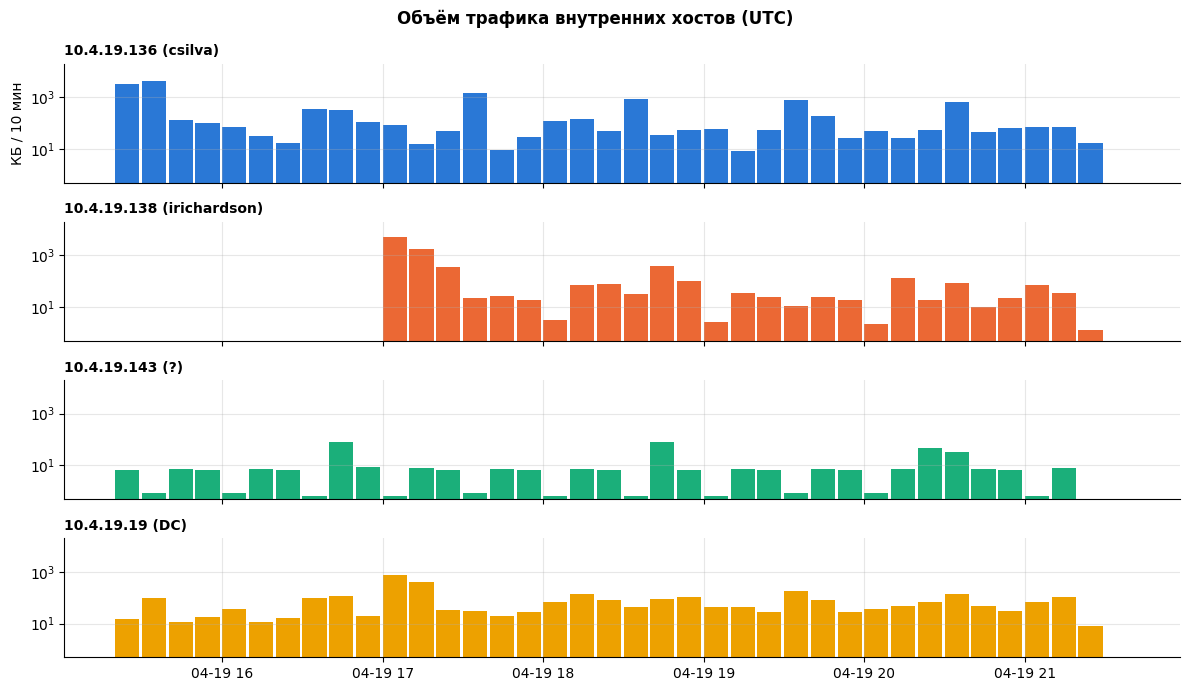

In [21]:
ip_pk = pkts[pkts["src_ip"].notna()]
grid = pd.date_range(ip_pk["dt"].min().floor("10min"), ip_pk["dt"].max().ceil("10min"), freq="10min")
fig, axes = plt.subplots(len(HOSTS), 1, figsize=(12, 7), sharex=True, sharey=True)
for ax, (i, h) in zip(axes, enumerate(HOSTS)):
    m = (ip_pk["src_ip"] == h) | (ip_pk["dst_ip"] == h)
    s = ip_pk[m].set_index("dt")["length"].resample("10min").sum().reindex(grid, fill_value=0) / 1e3
    ax.bar(s.index, s.values.clip(min=0.01), width=pd.Timedelta("9min"), color=PALETTE[i], align="edge")
    ax.set_yscale("log"); ax.set_ylim(0.5, 2e4)
    ax.set_title(f"{h} ({HOSTS[h]})", loc="left", fontsize=10)
axes[0].set_ylabel("КБ / 10 мин")
fig.suptitle("Объём трафика внутренних хостов (UTC)", fontweight="bold")
plt.tight_layout(); plt.show()

* `.136` (csilva) активен всё время; в начале — всплеск (загрузки около 15:30).
* `.138` (irichardson) появляется только в 17:02 — включение компьютера и вход пользователя: в первые минуты
  Windows скачивает обновления, отсюда пик.
* `.143` почти молчит: только служебный обмен с контроллером домена.

## 1.2. Распределение объёма сеансов: почему среднее «врёт»

Распределение объёмов сетевых сеансов не нормальное, у него «длинный хвост».

count        530.0
mean       36688.0
std       178328.0
min           54.0
25%         5802.0
50%         8450.0
75%        14158.0
max      2929075.0

среднее / медиана = 4.3;  MAD = 3514 Б;  IQR = 8357 Б
доля байт в 1 % самых крупных сеансов: 39%
K-S против нормального:     p = 1.2e-84
K-S против логнормального:  p = 1.0e-10


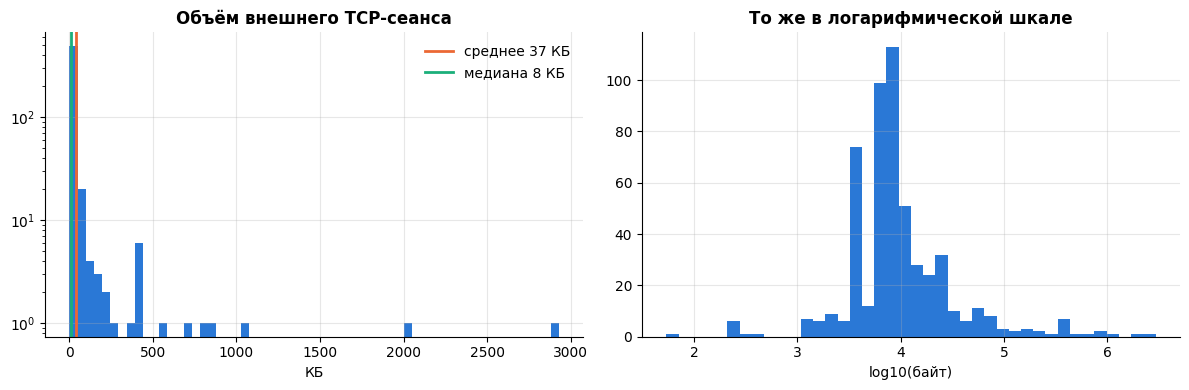

In [24]:
ext_tcp = sess[sess["external"] & (sess["l4"] == "TCP")].copy()
x = ext_tcp["bytes"].astype(float)
med, mad = x.median(), (x - x.median()).abs().median()
q1, q3 = x.quantile([0.25, 0.75])
print(x.describe().round(0).to_string())
print(f"\nсреднее / медиана = {x.mean() / med:.1f};  MAD = {mad:.0f} Б;  IQR = {q3 - q1:.0f} Б")
print(f"доля байт в 1 % самых крупных сеансов: {x.nlargest(max(1, len(x) // 100)).sum() / x.sum():.0%}")
lx = np.log10(x)
print("K-S против нормального:     p =", f"{st.kstest(x, st.norm(x.mean(), x.std()).cdf).pvalue:.1e}")
print("K-S против логнормального:  p =", f"{st.kstest(lx, st.norm(lx.mean(), lx.std()).cdf).pvalue:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(x / 1e3, bins=60, color=PALETTE[0])
axes[0].axvline(x.mean() / 1e3, color=PALETTE[1], lw=2, label=f"среднее {x.mean() / 1e3:.0f} КБ")
axes[0].axvline(med / 1e3, color=PALETTE[2], lw=2, label=f"медиана {med / 1e3:.0f} КБ")
axes[0].set_yscale("log"); axes[0].set_xlabel("КБ"); axes[0].legend(frameon=False)
axes[0].set_title("Объём внешнего TCP-сеанса")
axes[1].hist(lx, bins=40, color=PALETTE[0]); axes[1].set_xlabel("log10(байт)")
axes[1].set_title("То же в логарифмической шкале")
plt.tight_layout(); plt.show()

Нормальность отвергается и для самих объёмов, и для логарифмов: у распределения несколько «горбов».
Один из них — узкий пик около 3,2 КБ (log10 ≈ 3,5). Посмотрим, из чего он состоит:

In [25]:
spike = ext_tcp[ext_tcp["bytes"].between(3000, 3500)]
print(f"Сеансов в пике 3,0–3,5 КБ: {len(spike)}; из них к одному адресу:")
spike["srv"].value_counts().head(3)

Сеансов в пике 3,0–3,5 КБ: 68; из них к одному адресу:


,count
srv,
217.199.121.56,67
204.79.197.203,1


Почти весь пик — сеансы к **одному** серверу `217.199.121.56` одинакового размера. Многократно повторяющееся
одинаковое действие заметно даже на одномерной гистограмме; к этому серверу вернёмся в шагах 4 и 5.

Меры центра и разброса для таких распределений берём робастные: медиану и MAD,
а «необычность» сеанса — **робастным z-score** на логарифмической шкале: $z = 0{,}6745\,(x - \tilde{x}) / \mathrm{MAD}$,
порог $|z| > 3{,}5$.

In [26]:
lmed = lx.median(); lmad = (lx - lmed).abs().median()
ext_tcp["rz"] = 0.6745 * (lx - lmed) / lmad
cols = ["sid", "t", "cli", "srv", "sport", "name", "asn", "bytes", "rz", "truth"]
print("Сеансов с |z| > 3,5:", (ext_tcp["rz"].abs() > 3.5).sum())
ext_tcp.sort_values("rz", ascending=False)[cols].head(12)

Сеансов с |z| > 3,5: 38


,sid,t,cli,srv,sport,name,asn,bytes,rz,truth
22,22,2023-04-19 15:28:35.408632040+00:00,10.4.19.136,23.47.50.132,80,adl.windows.com,AS20940 Akamai International B.V.,2929075,9.346647,False
96,96,2023-04-19 15:36:42.979748011+00:00,10.4.19.136,104.168.53.18,443,askamoshopsi.com,AS36352 HostPapa,2004302,8.740309,True
73,73,2023-04-19 15:31:13.825134993+00:00,10.4.19.136,209.197.3.8,80,ctldl.windowsupdate.com,"AS16509 Amazon.com, Inc.",1034992,7.684063,False
1166,1166,2023-04-19 17:34:57.739505053+00:00,10.4.19.136,23.218.232.178,80,msedge.b.tlu.dl.delivery.mp.microsoft.com,AS20940 Akamai International B.V.,857197,7.382834,False
552,552,2023-04-19 17:04:37.789403915+00:00,10.4.19.138,72.21.81.240,80,11.au.download.windowsupdate.com,,809493,7.291323,False
1356,1356,2023-04-19 18:34:55.967902899+00:00,10.4.19.136,23.221.220.58,443,assets.msn.com,AS20940 Akamai International B.V.,724600,7.114262,False
91,91,2023-04-19 15:35:39.500739098+00:00,10.4.19.136,192.153.57.233,80,skigimeetroc.com,AS399629 BL Networks,543675,6.655153,True
522,522,2023-04-19 17:03:53.773152113+00:00,10.4.19.138,20.83.81.164,443,fe2cr.update.microsoft.com,AS8075 Microsoft Corporation,424882,6.261136,False
1049,1049,2023-04-19 17:16:50.483514071+00:00,10.4.19.138,204.79.197.200,443,edgeservices.bing.com,AS8068 Microsoft Corporation,423985,6.257758,False
992,992,2023-04-19 17:13:30.419992924+00:00,10.4.19.138,23.218.232.178,80,msedge.b.tlu.dl.delivery.mp.microsoft.com,AS20940 Akamai International B.V.,420961,6.246318,False


**Вывод (слайд «Выявление утечки данных»): статистика не отличает загрузку обновлений от загрузки вредоносного кода.**
В верхушке рядом стоят `adl.windows.com`, `windowsupdate.com`, `msedge…delivery` — и `askamoshopsi.com` (2 МБ по TLS) и
`skigimeetroc.com` (0,5 МБ). Выброс по объёму — только повод посмотреть контекст: имя, AS, протокол, время, кто ещё
обращался к этому серверу.

---
# 2. Новизна и локальность

Метрика локальности: люди и программы обращаются к небольшому устойчивому «рабочему множеству» адресатов.
Резкий рост числа адресатов, падение доли топ-5, рост энтропии и падение меры Жаккара — признаки смены поведения.
Добавим к метрикам ещё одну, полезную при расследовании: **сколько автономных систем впервые появились в сети**
в этом окне (ни один хост раньше к ним не обращался).

| Метрика | Смысл |
|---|---|
| $N$ | число разных внешних адресатов хоста в окне |
| $\mathrm{top5}$ | доля сеансов к пяти самым частым адресатам |
| $H_{norm} = -\sum p_j \log_2 p_j / \log_2 N$ | нормированная энтропия адресатов |
| $J = \lvert A_t \cap A_{t-1} \rvert / \lvert A_t \cup A_{t-1} \rvert$ | мера Жаккара с предыдущим окном |
| новые AS | AS, впервые встреченные в сети |

In [33]:
sess['t'].min(), sess['t'].max()

(Timestamp('2023-04-19 15:26:28.098378897+0000', tz='UTC'),
 Timestamp('2023-04-19 21:22:18.656853914+0000', tz='UTC'))

In [36]:
sess['cli'].unique()

array(['10.4.19.136', '10.4.19.19', '10.4.19.143', '10.4.19.138'],
      dtype=object)

In [38]:
#WIN = "30min"
WIN = "1h"
#WIN = "2h"
E = sess[sess["external"] & sess["cli"].str.startswith("10.4.19.")].copy()

E["w"] = E["t"].dt.floor(WIN)
rows, seen_asn, prev = [], set(), {}
for w, g in E.sort_values("t").groupby("w"):
    for h, gg in g.groupby("cli"):
        c = gg["srv"].value_counts()
        pj = c / c.sum()
        A = set(c.index)
        rows.append({"окно": w.strftime("%H:%M"), "хост": h, "сеансов": len(gg), "N": len(c),
                     "top5": c.iloc[:5].sum() / c.sum(),
                     "H_norm": float(-(pj * np.log2(pj)).sum() / np.log2(len(c))) if len(c) > 1 else 0.0,
                     "J": len(A & prev[h]) / len(A | prev[h]) if h in prev else np.nan,
                     "новые AS": ", ".join(sorted(set(gg["asn"].dropna()) - seen_asn))})
        prev[h] = A
    seen_asn |= set(g["asn"].dropna())
L = pd.DataFrame(rows)
L.round(2)

,окно,хост,сеансов,N,top5,H_norm,J,новые AS
0,15:00,10.4.19.136,64,41,0.31,0.96,NaN,"AS14618 Amazon.com, Inc., AS15169 Google LLC, AS16509 Amazon.com, ..."
1,16:00,10.4.19.136,63,29,0.48,0.90,0.13,
2,17:00,10.4.19.136,40,16,0.65,0.86,0.22,"AS3356 Level 3 Parent, LLC"
3,17:00,10.4.19.138,175,84,0.25,0.93,NaN,"AS22612 Namecheap, Inc., AS3356 Level 3 Parent, LLC, AS62005 BlueV..."
4,18:00,10.4.19.136,44,18,0.64,0.86,0.26,
5,18:00,10.4.19.138,11,10,0.55,0.99,0.03,
6,19:00,10.4.19.136,63,34,0.44,0.89,0.21,AS8070 Microsoft Corporation
7,19:00,10.4.19.138,6,6,0.83,1.00,0.07,
8,20:00,10.4.19.136,40,18,0.62,0.85,0.16,
9,20:00,10.4.19.138,12,11,0.50,0.99,0.13,


* 15:00 — начало записи: для первого окна «новым» выглядит всё, это не сигнал.
* **15:30, `.136`**: шесть новых для сети AS сразу — Amazon, ColoCrossing, BLNWX, Baltcom, Google, servinga.
  Google здесь — Firebase Storage, откуда скачан `Scan_Inv.zip`; Amazon — сертификат `www.ssl.com`; остальные четыре —
  небольшие хостинги, через которые пройдёт остальная вредоносная активность. Окно совпадает с цепочкой из части 1.
* **17:00, `.138`**: N = 81 и низкая доля топ-5 — но это **включение компьютера** (обновления, телеметрия).
  «Холодный старт» хоста всегда выглядит как всплеск новизны, это ложная тревога метрик локальности.
  Среди новых AS при этом есть два небольших хостинга — Namecheap и BlueVPS (те самые zip и соединение по IP).
* После 16:00 новых AS почти нет — на уровне AS поведение стабильно. А мера Жаккара по **IP-адресам** остаётся низкой
  (0–0,3): облачные сервисы каждый раз отвечают с других адресов. Для облаков устойчивость надо мерить по AS
  или доменам, а не по IP.
* BackConnect в 20:48 новой AS **не добавил**: `193.149.176.100` принадлежит той же AS BLNWX (хостинг), что и
  `skigimeetroc.com` в 15:35. Это возможная связь между эпизодами, но не доказательство: одна AS — ещё не один владелец.

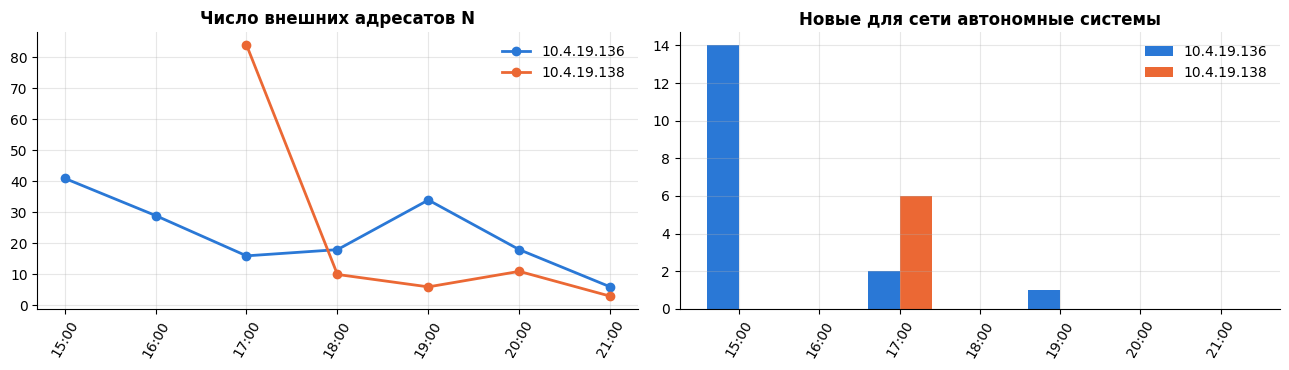

In [39]:
wins = sorted(L["окно"].unique())
L["n_new_as"] = L["новые AS"].map(lambda s: len([x for x in s.split(", ") if x]))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
xs = np.arange(len(wins))
for i, h in enumerate(["10.4.19.136", "10.4.19.138"]):
    d = L[L["хост"] == h].set_index("окно").reindex(wins)
    axes[0].plot(xs, d["N"], marker="o", lw=2, color=PALETTE[i], label=h)
    axes[1].bar(xs + (i - 0.5) * 0.4, d["n_new_as"].fillna(0), width=0.4, color=PALETTE[i], label=h)
for ax, title in zip(axes, ["Число внешних адресатов N", "Новые для сети автономные системы"]):
    ax.set_xticks(xs, wins, rotation=60); ax.set_title(title); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

---
# 3. Fumbling: ошибки и неудачи

Ищем систематические ошибки: соединения без ответа, NXDOMAIN, ICMP-ошибки,
обращения к «тёмным» адресам и спред источника — сколько разных целей он перебирает.

In [40]:
fails = sess[(sess["l4"] == "TCP") & sess["state"].isin(["нет ответа", "отклонён", "полуоткрыт"])]
print("Неудачные TCP-сеансы:")
display(fails[["t", "cli", "srv", "sport", "pkts_c2s", "pkts_s2c", "state", "asn", "name"]])

nxd = app[(app["kind"] == "dns_resp") & (app["rcode"] == 3)]
print("NXDOMAIN по хостам:")
display(nxd.groupby(["dst_ip", "name"]).size().rename("ответов"))

icmp = pkts[(pkts["l4"] == "ICMP")]
print("ICMP-сообщения: отправитель -> тип/код, вложенный пакет:")
display(icmp.groupby(["src_ip", "icmp_type", "icmp_code", "err_src", "err_dport"], dropna=False).size().rename("раз"))

Неудачные TCP-сеансы:


,t,cli,srv,sport,pkts_c2s,pkts_s2c,state,asn,name
1074,2023-04-19 17:17:38.782990932+00:00,10.4.19.138,85.239.53.73,80,5,1,отклонён,AS62005 BlueVPS OU,


NXDOMAIN по хостам:


dst_ip       name                                                                       
10.4.19.136  _ldap._tcp.default-first-site-name._sites.win-gp4jhck2jmv.boogienights.live     2
             _ldap._tcp.win-gp4jhck2jmv.boogienights.live                                    2
             wpad.boogienights.live                                                         82
10.4.19.138  dlmfz.joansstudio.store                                                         7
             htvprvudcuirn.boogienights.live                                                 1
             nobpc.joansstudio.store                                                        19
             pti.store.microsoft.com                                                         1
             wjbqfqttqdgk.boogienights.live                                                  1
             wpad.boogienights.live                                                         56
             xjmurjqikjcfq.boogienights.live                                                 1
10.4.19.143  _ldap._tcp.default-first-site-name._sites.win-gp4jhck2jmv.boogienights.live     3
             _ldap._tcp.win-gp4jhck2jmv.boogienights.live                                    3
Name: ответов, dtype: int64

ICMP-сообщения: отправитель -> тип/код, вложенный пакет:


src_ip       icmp_type  icmp_code  err_src     err_dport
10.4.19.136  3.0        3.0        10.4.19.19  49534.0      1
                                               49545.0      1
                                               50013.0      1
                                               50070.0      1
                                               52128.0      1
                                               52741.0      1
                                               53316.0      1
                                               53865.0      1
                                               56064.0      1
                                               56640.0      1
                                               57192.0      1
                                               59386.0      1
                                               59945.0      1
                                               60780.0      1
                                               60852.0      1
                                               61728.0      1
                                               62179.0      1
                                               62241.0      1
                                               63153.0      1
                                               63275.0      1
                                               63941.0      1
                                               64785.0      1
                                               65365.0      1
10.4.19.138  3.0        3.0        10.4.19.19  50058.0      1
                                               51215.0      1
                                               51458.0      1
                                               52591.0      1
                                               53011.0      1
                                               53433.0      1
                                               54952.0      1
                                               56382.0      1
                                               56667.0      1
                                               57282.0      1
                                               58564.0      1
                                               61972.0      1
                                               64133.0      1
Name: раз, dtype: int64

In [ ]:
live = set(pkts["src_ip"].dropna())                       # хоть раз отправляли пакет
local_dst = pkts["dst_ip"].dropna()
local_dst = local_dst[local_dst.str.startswith("10.4.19.") & ~local_dst.str.endswith(".255")]
print("Тёмные адреса внутри сегмента:", sorted(set(local_dst) - live) or "нет")

tcp_ext = sess[(sess["l4"] == "TCP")].copy()
tcp_ext["w"] = tcp_ext["t"].dt.floor("10min")
spread = tcp_ext.groupby(["cli", "w"]).agg(S_dst=("srv", "nunique"),
                                           S_port=("sport", "nunique"), N=("sid", "size"),
                                           fail=("state", lambda s: s.isin(["нет ответа", "отклонён", "полуоткрыт"]).mean()))
spread.sort_values("S_dst", ascending=False).head(5)

Тёмные адреса внутри сегмента: нет


S_dst  S_port    N      fail
cli         w                                                      
10.4.19.138 2023-04-19 17:00:00+00:00     62      10  251  0.000000
10.4.19.136 2023-04-19 15:30:00+00:00     25       8   45  0.000000
            2023-04-19 19:30:00+00:00     23       7   66  0.000000
10.4.19.138 2023-04-19 17:10:00+00:00     23      10  104  0.009615
10.4.19.136 2023-04-19 15:20:00+00:00     17       5   23  0.000000

In [42]:
#Посмотрим на ошибки DNS, исключив внутренний домен
nxd[~nxd['name'].str.endswith('boogienights.live')].groupby(["dst_ip", "name"]).size().rename("ответов")

dst_ip       name                   
10.4.19.138  dlmfz.joansstudio.store     7
             nobpc.joansstudio.store    19
             pti.store.microsoft.com     1
Name: ответов, dtype: int64

**Вывод шага 3: активной разведки сети нет.** Тёмных адресов нет, спред источников небольшой и почти без неудач
(максимум — запуск `.138` в 17:00, это обращения к десяткам адресов Microsoft), ICMP-сообщения —
«port unreachable» хостов на запоздавшие ответы DNS от контроллера домена.

Разберём NXDOMAIN — здесь легко ошибиться:
* `wpad.boogienights.live` — Windows ищет файл автонастройки прокси; NXDOMAIN — норма;
* `_ldap._tcp…` — поиск контроллера домена для сайта; тоже норма;
* `htvprvudcuirn`, `wjbqfqttqdgk`, `xjmurjqikjcfq` у `.138` — случайные имена, **похожие на DGA**. Это проверка,
  которую делают браузеры на движке Chromium (Edge, Chrome) при запуске: не подменяет ли DNS-сервер ответы NXDOMAIN.
  Признак: три имени из 7–15 букв подряд, один раз, в момент старта браузера;
* 26 ответов по двум именам в зоне `joansstudio.store` у `.138` в 17:12–17:15 — **подозрительно**: несуществующие
  поддомены, к которым браузер обращался многократно, — типичный след перенаправлений (TDS) в фишинговой цепочке.

Через полторы минуты после этого `.138` скачивает zip (часть 1), а ещё через 28 с пытается соединиться по IP с `85.239.53.73`,
но соединение не устанавливается (пять SYN без SYN-ACK, RST только через 75 с).

Отсутствие сканирования не значит отсутствие разведки: злоумышленник может узнавать о сети через сам домен
(запросы к контроллеру домена). Это проверим в шагах 6 и 7.

---
# 4. Биконинг

Вредоносное ПО регулярно «отмечается» на управляющем сервере. Признаки:
много сеансов к одному серверу, **малый разброс интервалов** между ними (коэффициент вариации $CV = \sigma/\mu$
и робастный аналог $\mathrm{MAD}/\mathrm{медиана}$), **одинаковый размер** сеансов.
Интервалы короче 1 с не учитываем — это параллельные соединения одного «опроса».

In [43]:
def beacon_stats(g):
    t = np.sort(g["start"].to_numpy())
    d = np.diff(t)
    d = d[d > 1.0]
    if len(d) < 5:
        return None
    med = np.median(d)
    sizes = g["bytes_s2c"]
    return {"сеансов": len(t), "период, с": med, "CV": d.std() / d.mean(),
            "MAD/мед": np.median(np.abs(d - med)) / med,
            "доля модального размера": sizes.value_counts().iloc[0] / len(sizes),
            "часов": (t[-1] - t[0]) / 3600}


rows = []
for (c, s, p), g in sess[sess["l4"] == "TCP"].groupby(["cli", "srv", "sport"]):
    r = beacon_stats(g)
    if r:
        rows.append({"клиент": c, "сервер": s, "порт": p, "имя": g["name"].iloc[0], **r, "внешний": g["external"].iloc[0]})
B = pd.DataFrame(rows).sort_values("CV")
B.round(3).head(12)

,клиент,сервер,порт,имя,сеансов,"период, с",CV,MAD/мед,доля модального размера,часов,внешний
7,10.4.19.136,217.199.121.56,443,skansnekssky.com,69,301.777,0.037,0.001,0.957,5.684,True
20,10.4.19.143,10.4.19.19,445,win-gp4jhck2jmv.boogienights.live,30,900.002,0.418,0.000,0.700,5.750,False
5,10.4.19.136,20.54.25.4,443,array616.prod.do.dsp.mp.microsoft.com,9,2169.272,0.440,0.247,0.333,5.140,True
2,10.4.19.136,10.4.19.19,445,win-gp4jhck2jmv.boogienights.live,31,899.971,0.463,0.073,0.194,5.851,False
8,10.4.19.136,51.104.162.168,443,array604.prod.do.dsp.mp.microsoft.com,10,1998.482,0.606,0.698,0.400,5.597,True
14,10.4.19.138,10.4.19.19,445,win-gp4jhck2jmv.boogienights.live,26,899.939,0.617,0.000,0.192,4.150,False
4,10.4.19.136,20.191.46.109,443,array601.prod.do.dsp.mp.microsoft.com,6,2415.857,0.696,0.571,0.333,4.874,True
9,10.4.19.136,51.104.167.186,443,array607.prod.do.dsp.mp.microsoft.com,25,697.179,0.816,0.874,0.200,5.580,True
3,10.4.19.136,10.4.19.19,49669,win-gp4jhck2jmv.boogienights.live,28,752.975,0.829,0.908,0.250,5.816,False
0,10.4.19.136,10.4.19.19,135,win-gp4jhck2jmv.boogienights.live,30,752.972,0.829,0.908,0.400,5.816,False


Самый регулярный канал — `.136 → skansnekssky.com:443`: **69 сеансов с периодом 301,8 с (≈ 5 мин), CV = 0,04**,
почти все ответы сервера одного размера, шесть часов без перерыва.

Но регулярность сама по себе не признак вредоносности. Рядом — служебные каналы Windows:
`.143`, `.138`, `.136` обращаются к контроллеру домена по SMB ровно раз в 15 минут (медианный интервал 900 с),
а клиенты доставки обновлений Microsoft (`array6xx…dsp.mp.microsoft.com`) — раз в 10–40 минут. Отличие C2 — **сочетание**:
внешний адрес, редкая AS, TLS с самоподписанным сертификатом (часть 1), постоянный размер, работа без пауз.

Посмотрим на сеансы во времени и на автокорреляцию — ещё один способ найти период, не зная его заранее.

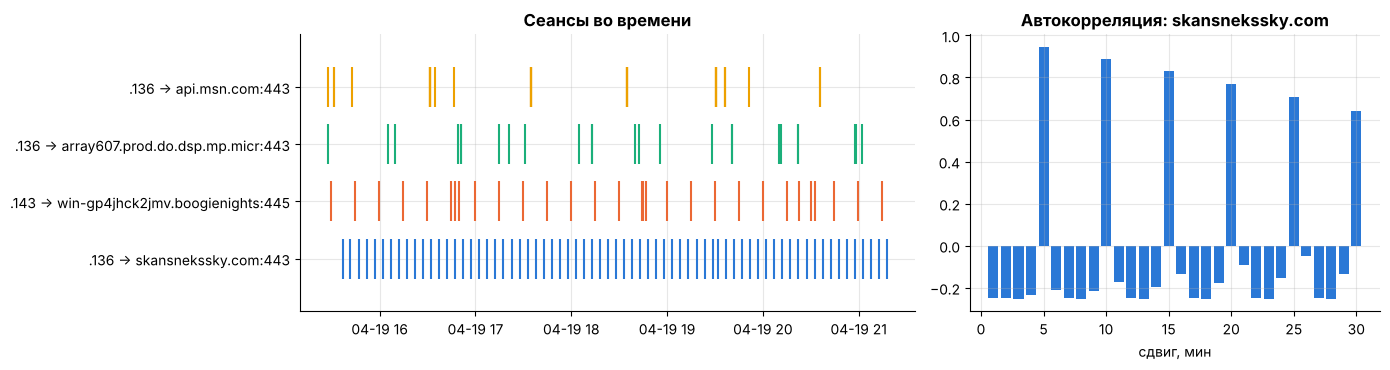

Максимум автокорреляции на сдвиге 5 мин


In [ ]:
cand = [("10.4.19.136", "217.199.121.56", 443), ("10.4.19.143", "10.4.19.19", 445),
        ("10.4.19.136", "51.104.167.186", 443), ("10.4.19.136", "204.79.197.203", 443)]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [3, 2]})
for i, (c, s, p) in enumerate(cand):
    g = sess[(sess["cli"] == c) & (sess["srv"] == s) & (sess["sport"] == p)]
    nm = g["name"].iloc[0] or s
    axes[0].eventplot(g["t"].dt.tz_localize(None), lineoffsets=i, colors=PALETTE[i], linelengths=0.7)
axes[0].set_yticks(range(len(cand)), [f"{c[-4:]} → {(sess.loc[sess['srv'] == s, 'name'].iloc[0] or s)[:28]}:{p}"
                                      for c, s, p in cand])
axes[0].set_title("Сеансы во времени")

g = sess[(sess["cli"] == "10.4.19.136") & (sess["srv"] == "217.199.121.56")]
cnt = g.set_index("t")["sid"].resample("1min").size()
lags = np.arange(1, 31)
acf = [cnt.autocorr(l) for l in lags]
axes[1].bar(lags, acf, color=PALETTE[0])
axes[1].set_xlabel("сдвиг, мин"); axes[1].set_title("Автокорреляция: skansnekssky.com")
plt.tight_layout(); plt.show()
print("Максимум автокорреляции на сдвиге", lags[int(np.argmax(acf))], "мин")

Пики автокорреляции на 5, 10, 15… минутах — период опроса, найденный без каких-либо предположений.

---
# 5. Машинное обучение без учителя

Правила из части 1 описывают известное. Методы поиска аномалий без учителя не требуют ни правил, ни разметки:
они ищут объекты, **непохожие на большинство**. Проверим, найдут ли они то же самое — и чего не найдут.

## 5.1. Признаки сеанса

Берём внешние TCP-сеансы и описываем каждый **только поведением**, без TI-фида и без правил:

| Признак | Смысл |
|---|---|
| `log_out`, `log_in` | объём к серверу и от сервера (log10 байт) |
| `log_pkts`, `log_dur` | число пакетов, длительность |
| `pl_out`, `pl_in` | средний размер полезной нагрузки пакета в каждую сторону |
| `ratio` | асимметрия: log10(вход / выход) |
| `tls`, `http`, `other` | протокол по первым байтам (не по порту!) |
| `log_asn_pop` | «популярность» AS: сколько сеансов дампа ушло в эту AS |
| `no_name` | у адреса нет имени (DNS/SNI/Host) |

In [44]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA

X0 = sess[sess["external"] & (sess["l4"] == "TCP")].copy()
X0["asn"] = X0["asn"].fillna("?")
asn_pop = X0["asn"].map(X0["asn"].value_counts())
feat = pd.DataFrame({
    "log_out": np.log10(X0["bytes_c2s"] + 1), "log_in": np.log10(X0["bytes_s2c"] + 1),
    "log_pkts": np.log10(X0["pkts"]), "log_dur": np.log10(X0["duration"] + 1e-3),
    "pl_out": X0["pl_c2s"] / X0["pkts_c2s"].clip(lower=1), "pl_in": X0["pl_s2c"] / X0["pkts_s2c"].clip(lower=1),
    "ratio": np.log10((X0["bytes_s2c"] + 1) / (X0["bytes_c2s"] + 1)),
    "tls": (X0["proto"] == "TLS").astype(int), "http": (X0["proto"] == "HTTP").astype(int),
    "other": (~X0["proto"].isin(["TLS", "HTTP", "нет данных"])).astype(int),
    "log_asn_pop": np.log10(asn_pop), "no_name": (X0["name"] == "").astype(int),
}, index=X0.index)
Z = StandardScaler().fit_transform(feat)
print("Сеансов:", Z.shape[0], "| признаков:", Z.shape[1], "| из них в эталоне:", X0["truth"].sum())
feat.describe().round(2)

Сеансов: 530 | признаков: 12 | из них в эталоне: 82


,log_out,log_in,log_pkts,log_dur,pl_out,pl_in,ratio,tls,http,other,log_asn_pop,no_name
count,530.00,530.00,530.00,530.00,530.00,530.00,530.00,530.0,530.00,530.00,530.00,530.00
mean,3.38,3.79,1.48,1.06,145.24,306.23,0.40,0.9,0.08,0.01,2.00,0.02
std,0.43,0.59,0.34,1.09,153.65,257.48,0.43,0.3,0.27,0.08,0.49,0.12
min,1.74,0.00,0.00,-3.00,0.00,0.00,-1.74,0.0,0.00,0.00,0.00,0.00
25%,3.12,3.59,1.30,-0.13,72.53,164.20,0.27,1.0,0.00,0.00,1.84,0.00
50%,3.31,3.77,1.45,1.61,95.98,234.56,0.33,1.0,0.00,0.00,1.97,0.00
75%,3.54,3.94,1.54,1.87,149.77,371.82,0.56,1.0,0.00,0.00,2.39,0.00
max,5.18,6.46,3.37,4.30,1184.72,1389.21,2.34,1.0,1.00,1.00,2.39,1.00


## 5.2. Isolation Forest

Isolation Forest строит случайные деревья, разрезая пространство признаков случайными порогами.
Аномальную точку удаётся «изолировать» за малое число разрезов, поэтому средняя глубина листа — мера необычности.

In [46]:
iso = IsolationForest(n_estimators=500, random_state=0).fit(Z)
X0["iso"] = -iso.score_samples(Z)                       # больше — необычнее
X0["rank"] = X0["iso"].rank(ascending=False).astype(int)
top = X0.sort_values("iso", ascending=False).head(20)
top[["rank", "t", "cli", "srv", "sport", "name", "asn", "proto", "bytes", "truth", "iso"]]

,rank,t,cli,srv,sport,name,asn,proto,bytes,truth,iso
3,1,2023-04-19 15:26:29.348495007+00:00,10.4.19.136,20.114.58.89,443,,AS8075 Microsoft Corporation,нет данных,54,False,0.740445
1900,2,2023-04-19 20:48:00.160043955+00:00,10.4.19.136,193.149.176.100,443,,AS399629 BL Networks,неизвестно,9410,True,0.716161
1074,3,2023-04-19 17:17:38.782990932+00:00,10.4.19.138,85.239.53.73,80,,AS62005 BlueVPS OU,нет данных,384,True,0.697960
22,4,2023-04-19 15:28:35.408632040+00:00,10.4.19.136,23.47.50.132,80,adl.windows.com,AS20940 Akamai International B.V.,HTTP,2929075,False,0.691996
1903,5,2023-04-19 20:49:33.534853935+00:00,10.4.19.136,193.149.176.100,443,,AS399629 BL Networks,неизвестно,2270,True,0.690254
1901,6,2023-04-19 20:49:11.492110014+00:00,10.4.19.136,193.149.176.100,443,,AS399629 BL Networks,неизвестно,2944,True,0.686940
16,7,2023-04-19 15:28:12.781172991+00:00,10.4.19.136,23.218.232.165,80,,AS20940 Akamai International B.V.,нет данных,216,False,0.672384
552,8,2023-04-19 17:04:37.789403915+00:00,10.4.19.138,72.21.81.240,80,11.au.download.windowsupdate.com,,HTTP,809493,False,0.670713
73,9,2023-04-19 15:31:13.825134993+00:00,10.4.19.136,209.197.3.8,80,ctldl.windowsupdate.com,"AS16509 Amazon.com, Inc.",HTTP,1034992,False,0.667809
91,10,2023-04-19 15:35:39.500739098+00:00,10.4.19.136,192.153.57.233,80,skigimeetroc.com,AS399629 BL Networks,HTTP,543675,True,0.666053


Как оценить результат? У нас есть эталон: посмотрим, на каких местах рейтинга оказались сеансы к каждому
вредоносному адресу, и долю «попаданий» среди первых k.

In [47]:
def rank_report(df, score_col):
    r = df[df["truth"]].groupby("srv")[score_col].agg(
        лучший_ранг=lambda s: int(df[score_col].rank(ascending=False)[s.index].min()),
        медианный_ранг=lambda s: int(df[score_col].rank(ascending=False)[s.index].median()),
        сеансов="size")
    r["что это"] = r.index.map(TRUTH)
    return r.sort_values("лучший_ранг")


display(rank_report(X0, "iso"))
for k in (10, 20, 50):
    print(f"precision@{k}: {X0.nlargest(k, 'iso')['truth'].mean():.2f}")

,лучший_ранг,медианный_ранг,сеансов,что это
srv,,,,
193.149.176.100,2,5,3,BackConnect IcedID (Unit 42)
85.239.53.73,3,3,1,"соединение по IP после загрузки zip (наш вывод, часть 1)"
192.153.57.233,10,10,1,"загрузчик IcedID, skigimeetroc.com (Unit 42)"
104.168.53.18,11,75,4,"C2 IcedID, askamoshopsi.com (Unit 42)"
80.77.25.175,13,13,1,TDS-перенаправление (Unit 42)
66.29.147.117,24,24,1,"загрузка zip, cotecsecuritygroup.com (наш вывод, часть 1)"
142.251.32.234,33,71,2,Firebase Storage (Google): Scan_Inv.zip по ссылке из 302 (часть 1)
217.199.121.56,150,430,69,"C2 IcedID, skansnekssky.com (Unit 42)"


precision@10: 0.50
precision@20: 0.35
precision@50: 0.20


* Шесть из восьми адресов эталона — **в первых 25 местах из 530**, хотя Isolation Forest ничего не знает ни о TI-фиде,
  ни о правилах. Выше всех — сеансы BackConnect (443 без TLS, нет имени), неудачное соединение `.138` по IP,
  загрузка 2 МБ с `askamoshopsi.com`. Загрузка архива с Firebase Storage — лишь на 29-м месте.
* Ложные срабатывания — крупные загрузки обновлений и одиночные пакеты от соединений, начавшихся до записи дампа.
* **69 сеансов биконинга к `skansnekssky.com` оказываются в середине рейтинга** (медианный ранг — сотни).
  Каждый такой сеанс выглядит заурядно: небольшой TLS-обмен. А раз их много и они одинаковые, они образуют
  собственную плотную группу — и для метода, ищущего «одиночек», перестают быть аномалией. Это **эффект маскировки**.

## 5.3. Кластеризация: DBSCAN и «монокультурные» кластеры

Если вредоносное поведение массово и однообразно, его выдаёт не одиночество, а **кластер**.
DBSCAN объединяет точки, у которых достаточно соседей в радиусе `eps`; выбросы получают метку −1.
Для каждого кластера посмотрим, сколько в нём разных серверов: кластер из десятков сеансов к **одному**
серверу редкой AS — подозрителен.

In [48]:
X0["cl"] = DBSCAN(eps=0.5, min_samples=5).fit_predict(Z)
clusters = X0.groupby("cl").agg(сеансов=("sid", "size"), серверов=("srv", "nunique"),
                                главный_сервер=("srv", lambda s: s.value_counts().index[0]),
                                его_доля=("srv", lambda s: s.value_counts().iloc[0] / len(s)),
                                AS=("asn", lambda s: s.value_counts().index[0]),
                                в_эталоне=("truth", "mean"))
clusters.sort_values("сеансов", ascending=False).round(2)

,сеансов,серверов,главный_сервер,его_доля,AS,в_эталоне
cl,,,,,,
-1,244,107,204.79.197.200,0.09,AS8068 Microsoft Corporation,0.06
1,77,43,52.185.211.133,0.08,AS8075 Microsoft Corporation,0.00
5,67,1,217.199.121.56,1.00,AS20910 SIA BITE Latvija,1.00
0,64,7,51.104.167.186,0.39,AS8075 Microsoft Corporation,0.00
2,18,9,204.79.197.203,0.50,AS8068 Microsoft Corporation,0.00
3,13,8,52.137.108.250,0.23,AS8075 Microsoft Corporation,0.00
4,10,9,40.126.24.149,0.20,AS8075 Microsoft Corporation,0.00
8,10,4,20.242.220.11,0.50,AS8075 Microsoft Corporation,0.00
7,9,3,204.79.197.203,0.78,AS8068 Microsoft Corporation,0.00


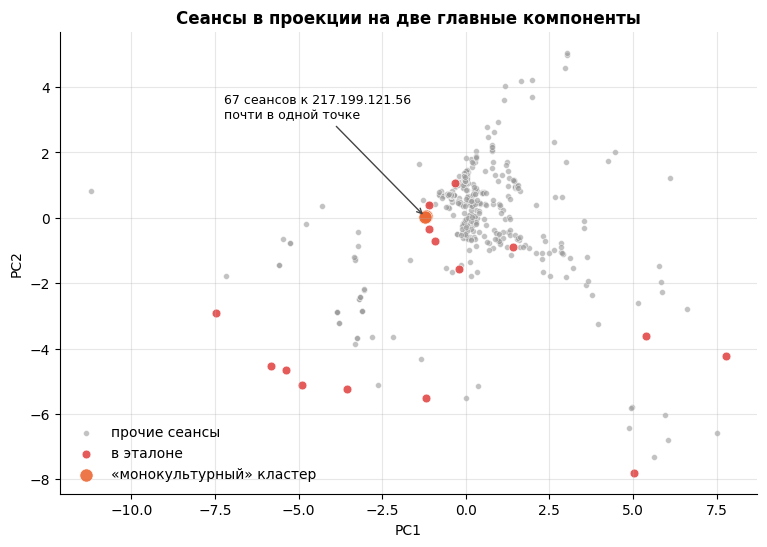

In [49]:
P2 = PCA(n_components=2, random_state=0).fit_transform(Z)
fig, ax = plt.subplots(figsize=(9, 6))
mono = clusters[(clusters["его_доля"] > 0.9) & (clusters.index >= 0)].index
for lab, color, name in [("other", GRAY, "прочие сеансы"), ("truth", PALETTE[7], "в эталоне"),
                         ("mono", PALETTE[1], "«монокультурный» кластер")]:
    m = {"other": ~X0["cl"].isin(mono) & ~X0["truth"], "mono": X0["cl"].isin(mono),
         "truth": X0["truth"] & ~X0["cl"].isin(mono)}[lab]
    ax.scatter(P2[m.to_numpy(), 0], P2[m.to_numpy(), 1], s={"other": 18, "truth": 40, "mono": 90}[lab], c=color,
               label=name, alpha=0.6 if lab == "other" else 0.9, edgecolors="white", linewidths=0.5)
mono_m = X0["cl"].isin(mono).to_numpy()
cx, cy = P2[mono_m, 0].mean(), P2[mono_m, 1].mean()
ax.annotate(f"{mono_m.sum()} сеансов к {X0.loc[mono_m, 'srv'].iloc[0]}\nпочти в одной точке", (cx, cy),
            xytext=(cx - 6, cy + 3), arrowprops={"arrowstyle": "->", "color": "#444444"}, fontsize=9)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(frameon=False, loc="lower left")
ax.set_title("Сеансы в проекции на две главные компоненты")
plt.show()

DBSCAN выделил кластер, в котором **все сеансы идут к одному адресу** `217.199.121.56` (Baltcom SIA, Латвия) —
это и есть биконинг. Остальные кластеры смешанные: от нескольких до десятков серверов Microsoft и Akamai.



## 5.4. Другой уровень агрегации: пара «хост – сервер»

Вывод из 5.2–5.3: **выбор объекта анализа важнее выбора алгоритма**. Опишем не сеанс, а всю историю общения хоста
с сервером: сколько сеансов, насколько регулярны интервалы (шаг 4), насколько одинаковы размеры, сколько длилась связь.

In [50]:
rows = []
for (c, s), g in X0.groupby(["cli", "srv"]):
    t = np.sort(g["start"].to_numpy()); d = np.diff(t); d = d[d > 1]
    rows.append({"cli": c, "srv": s, "name": g["name"].iloc[0], "asn": g["asn"].iloc[0], "truth": g["truth"].iloc[0],
                 "log_n": np.log10(len(g)), "cv_int": d.std() / d.mean() if len(d) >= 3 else 1.0,
                 "same_size": g["bytes_s2c"].value_counts().iloc[0] / len(g),
                 "log_bytes": np.log10(g["bytes"].sum()), "log_span": np.log10(t[-1] - t[0] + 1),
                 "log_asn_pop": np.log10(asn_pop[g.index].iloc[0]), "no_name": int(g["name"].iloc[0] == ""),
                 "other": int((g["proto"] == "неизвестно").any())})
A = pd.DataFrame(rows)
FA = ["log_n", "cv_int", "same_size", "log_bytes", "log_span", "log_asn_pop", "no_name", "other"]
ZA = StandardScaler().fit_transform(A[FA])
A["iso"] = -IsolationForest(n_estimators=500, random_state=0).fit(ZA).score_samples(ZA)
A.sort_values("iso", ascending=False).head(12)[["cli", "srv", "name", "asn", "log_n", "cv_int", "same_size", "iso", "truth"]].round(2)

,cli,srv,name,asn,log_n,cv_int,same_size,iso,truth
23,10.4.19.136,193.149.176.100,,AS399629 BL Networks,0.48,1.00,0.33,0.76,True
61,10.4.19.136,217.199.121.56,skansnekssky.com,AS20910 SIA BITE Latvija,1.84,0.04,0.96,0.70,True
155,10.4.19.138,204.79.197.200,edgeservices.bing.com,AS8068 Microsoft Corporation,1.26,2.12,0.06,0.68,False
161,10.4.19.138,23.214.44.116,x1.c.lencr.org,"AS16625 Akamai Technologies, Inc.",0.60,0.12,1.00,0.65,False
25,10.4.19.136,20.114.58.89,,AS8075 Microsoft Corporation,0.00,1.00,1.00,0.65,False
204,10.4.19.138,85.239.53.73,,AS62005 BlueVPS OU,0.00,1.00,1.00,0.65,True
104,10.4.19.136,80.77.25.175,,AS207408 servinga GmbH,0.00,1.00,1.00,0.64,True
130,10.4.19.138,173.223.109.212,storeedgefd.dsx.mp.microsoft.com,"AS16625 Akamai Technologies, Inc.",1.15,1.12,0.07,0.63,False
63,10.4.19.136,23.218.232.165,,AS20940 Akamai International B.V.,0.00,1.00,1.00,0.61,False
56,10.4.19.136,204.79.197.203,api.msn.com,AS8068 Microsoft Corporation,1.51,1.16,0.09,0.61,False


In [51]:
display(rank_report(A.assign(sid=A.index), "iso"))
for k in (5, 10, 20):
    print(f"precision@{k}: {A.nlargest(k, 'iso')['truth'].mean():.2f}  (пар всего: {len(A)})")

,лучший_ранг,медианный_ранг,сеансов,что это
srv,,,,
193.149.176.100,1,1,1,BackConnect IcedID (Unit 42)
217.199.121.56,2,2,1,"C2 IcedID, skansnekssky.com (Unit 42)"
85.239.53.73,6,6,1,"соединение по IP после загрузки zip (наш вывод, часть 1)"
80.77.25.175,7,7,1,TDS-перенаправление (Unit 42)
104.168.53.18,12,12,1,"C2 IcedID, askamoshopsi.com (Unit 42)"
142.251.32.234,19,19,1,Firebase Storage (Google): Scan_Inv.zip по ссылке из 302 (часть 1)
192.153.57.233,27,27,1,"загрузчик IcedID, skigimeetroc.com (Unit 42)"
66.29.147.117,37,37,1,"загрузка zip, cotecsecuritygroup.com (наш вывод, часть 1)"


precision@5: 0.40  (пар всего: 205)
precision@10: 0.40  (пар всего: 205)
precision@20: 0.30  (пар всего: 205)


На уровне пар биконинг поднимается на второе место: 69 сеансов с CV = 0,04 и одинаковым размером — редкое сочетание.

**Выводы шага 5**
* Поиск аномалий без учителя нашёл почти всю вредоносную инфраструктуру, не зная ни одного индикатора.
  Это хороший **способ приоритизации**, но не детектор: в верхушке рейтинга есть и легитимные загрузки обновлений.
* Массовое однообразное поведение (биконинг) маскируется на уровне отдельных сеансов. Его выдают кластеризация
  («монокультурный» кластер) и агрегация на уровне «хост – сервер».
* Сравните с частью 1: правила нашли то же быстрее, во многом **благодаря TI-фиду**. Без `TI` у BackConnect останутся
  «по IP», «порт≠протокол», «редкая AS», у C2 — «редкая AS», «редкий домен», «самоподписанный». Аналоги части этих
  признаков есть и в ML (`no_name`, `other`, `log_asn_pop`), сертификата — нет (см. задание 5).
* Хуже всего обнаруживается загрузка архива с Firebase Storage: 29-е место среди сеансов, 19-е среди пар, ни одного
  балла по правилам части 1. Это обычный TLS-сеанс к Google. Злоупотребление легитимными облаками по метаданным
  одного сеанса почти не видно — его выдаёт цепочка событий (перенаправление `302` из части 1).


---
# 6. Граф связей

## 6.1. Хосты и автономные системы

Граф «хост — AS» компактнее графа «хост — IP»: сотни адресов Microsoft и Akamai сворачиваются в несколько узлов.
Узлы-«хабы» (общие для всех хостов облака) — фон. Интересны **листья**: AS, с которой общался ровно один хост.

AS-хабы (общие для хостов): ['', 'AS15169 Google LLC', 'AS16509 Amazon.com, Inc.', 'AS16625 Akamai Technologies, Inc.', 'AS20940 Akamai International B.V.', 'AS3356 Level 3 Parent, LLC', 'AS8068 Microsoft Corporation', 'AS8075 Microsoft Corporation']
AS-листья: {'AS14618 Amazon.com, Inc.': '10.4.19.136', 'AS207408 servinga GmbH': '10.4.19.136', 'AS20910 SIA BITE Latvija': '10.4.19.136', 'AS36352 HostPapa': '10.4.19.136', 'AS399629 BL Networks': '10.4.19.136', 'AS8070 Microsoft Corporation': '10.4.19.136', 'AS22612 Namecheap, Inc.': '10.4.19.138', 'AS62005 BlueVPS OU': '10.4.19.138', 'AS701 Verizon Business': '10.4.19.138'}


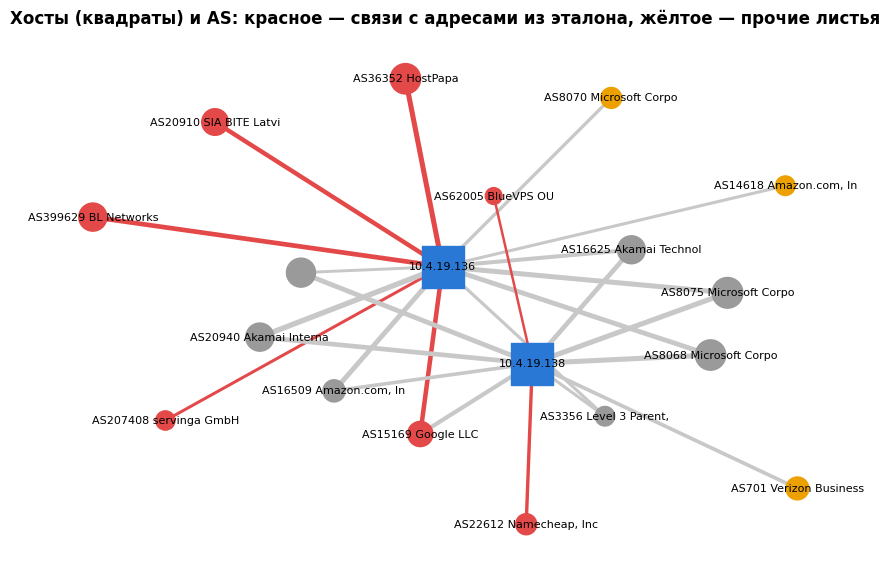

In [52]:
ext_s = sess[sess["external"] & sess["cli"].str.startswith("10.4.19.")]
G = nx.Graph()
for (h, a), g in ext_s.groupby(["cli", "asn"]):
    G.add_node(h, kind="host")
    G.add_node(a, kind="asn", bytes=0)
    G.add_edge(h, a, sessions=len(g), bytes=int(g["bytes"].sum()), truth=bool(g["truth"].any()))
    G.nodes[a]["bytes"] += int(g["bytes"].sum())
deg = dict(G.degree())
leaves = [n for n, d in G.nodes(data=True) if d["kind"] == "asn" and deg[n] == 1]
print("AS-хабы (общие для хостов):", sorted(n for n, d in G.nodes(data=True) if d["kind"] == "asn" and deg[n] > 1))
print("AS-листья:", {n: next(iter(G.neighbors(n))) for n in leaves})

fig, ax = plt.subplots(figsize=(11, 7))
pos = nx.spring_layout(G, seed=7, k=0.9, weight=None)
hosts = [n for n, d in G.nodes(data=True) if d["kind"] == "host"]
asns = [n for n, d in G.nodes(data=True) if d["kind"] == "asn"]
bad_as = {a for u, a, d in G.edges(data=True) if d["truth"]} | {u for u, a, d in G.edges(data=True) if d["truth"]}
nx.draw_networkx_edges(G, pos, ax=ax, width=[0.5 + np.log10(d["bytes"]) / 2 for _, _, d in G.edges(data=True)],
                       edge_color=[PALETTE[7] if d["truth"] else "#c8c8c8" for _, _, d in G.edges(data=True)])
nx.draw_networkx_nodes(G, pos, nodelist=hosts, node_color=PALETTE[0], node_size=900, node_shape="s", ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=asns, ax=ax, node_size=[80 + 40 * np.log10(G.nodes[a]["bytes"]) ** 2 / 4 for a in asns],
                       node_color=[PALETTE[7] if a in bad_as else (PALETTE[3] if a in leaves else GRAY) for a in asns])
nx.draw_networkx_labels(G, pos, {n: n if n in hosts else n[:22] for n in G.nodes}, font_size=8, ax=ax)
ax.set_title("Хосты (квадраты) и AS: красное — связи с адресами из эталона, жёлтое — прочие листья")
ax.axis("off"); plt.show()

Почти все AS, через которые шла вредоносная активность, — листья: каждой пользовался один хост. Исключение — Google:
архив первой стадии скачан из Firebase Storage, и красное ребро ведёт в общий для всех хаб. Собственная инфраструктура
злоумышленника «одноразовая» и не пересекается с облаками, а вот арендованные легитимные облака на графе по AS не выделяются.
Единственный «посторонний» лист — Amazon: это загрузка сертификата `www.ssl.com` в 15:34, между загрузкой архива и обращением
к `skigimeetroc.com` (вероятно, Windows проверяла цифровую подпись запущенного файла). CDN обновлений (StackPath, Level3,
Edgecast) — общие для обоих хостов узлы.



## 6.2. «До» и «после»

Разделим сеансы хоста `.136` моментом первого обращения к вредоносной инфраструктуре $T_0$ и посмотрим,
какие узлы графа появились после него.

In [54]:
T0 = sess.loc[sess["truth"], "t"].min()
print("T0 =", T0)
h136 = ext_s[ext_s["cli"] == "10.4.19.136"]
before, after = set(h136.loc[h136["t"] < T0, "asn"]), set(h136.loc[h136["t"] >= T0, "asn"])
new = after - before
print("AS только после T0:")
display(h136[h136["asn"].isin(new)].groupby(["asn", "srv", "name"]).agg(
    сеансов=("sid", "size"), первый=("t", "min"), байт=("bytes", "sum")).sort_values("первый"))

T0 = 2023-04-19 15:31:07.868664980+00:00
AS только после T0:


,,,сеансов,первый,байт
asn,srv,name,,,
AS207408 servinga GmbH,80.77.25.175,,1,2023-04-19 15:31:07.868664980+00:00,2247
"AS16625 Akamai Technologies, Inc.",23.36.63.240,go.microsoft.com,4,2023-04-19 15:32:18.566252947+00:00,12468
"AS14618 Amazon.com, Inc.",54.145.90.68,www.ssl.com,1,2023-04-19 15:34:33.333297968+00:00,2784
AS399629 BL Networks,192.153.57.233,skigimeetroc.com,1,2023-04-19 15:35:39.500739098+00:00,543675
AS36352 HostPapa,104.168.53.18,askamoshopsi.com,4,2023-04-19 15:36:41.231173992+00:00,2037731
AS20910 SIA BITE Latvija,217.199.121.56,skansnekssky.com,69,2023-04-19 15:36:44.197117090+00:00,229333
,192.229.211.108,ocsp.digicert.com,1,2023-04-19 16:40:13.591420889+00:00,1647
"AS3356 Level 3 Parent, LLC",8.252.77.126,ctldl.windowsupdate.com,1,2023-04-19 17:51:44.197247982+00:00,1938
AS8070 Microsoft Corporation,20.141.10.212,fp-afd.azurefd.us,1,2023-04-19 19:30:24.963291883+00:00,6794


## 6.3. Связи внутри сети: было ли распространение?

Боковое перемещение (lateral movement) выглядит в графе как новые рёбра **между рабочими станциями** (SMB, RDP, WinRM,
RPC) или как необычные обращения к серверам. Построим внутренний граф по сеансам TCP.

In [55]:
inner = sess[~sess["external"] & (sess["l4"] == "TCP")]
GI = nx.DiGraph()
for (c, s), g in inner.groupby(["cli", "srv"]):
    GI.add_edge(c, s, ports=sorted(set(g["sport"].astype(int))), n=len(g))
for c, s, d in GI.edges(data=True):
    print(f"{c:>12} → {s:<12} сеансов {d['n']:3}  порты {d['ports']}")
ws = [n for n in GI if n != "10.4.19.19"]
print("Рёбер между рабочими станциями:", sum(1 for c, s in GI.edges if c in ws and s in ws))

 10.4.19.136 → 10.4.19.19   сеансов 144  порты [88, 135, 139, 389, 445, 49669, 49684]
 10.4.19.138 → 10.4.19.19   сеансов 266  порты [53, 88, 135, 139, 389, 445, 49669, 49684]
 10.4.19.143 → 10.4.19.19   сеансов  63  порты [88, 135, 389, 445, 49669, 49684]
Рёбер между рабочими станциями: 0


Рабочие станции общаются **только с контроллером домена** — горизонтального перемещения по SMB/RDP в дампе нет.
Но злоумышленнику и не нужно ходить по станциям, чтобы изучить сеть: достаточно спросить контроллер домена.
Сопоставим по времени сеансы BackConnect (`193.149.176.100`) и сеансы `.136` к контроллеру домена.

In [56]:
bc = sess[sess["srv"] == "193.149.176.100"]
dc = sess[(sess["cli"] == "10.4.19.136") & (sess["srv"] == "10.4.19.19") & (sess["l4"] == "TCP")]
win = (bc["t"].min() - pd.Timedelta("3min"), bc["t"].min() + pd.Timedelta("5min"))
both = pd.concat([bc.assign(канал="BackConnect"), dc.assign(канал="к DC")])
both = both[(both["t"] >= win[0]) & (both["t"] <= win[1])].sort_values("t")
display(both[["t", "канал", "srv", "sport", "pkts", "bytes", "duration"]])

smb = dc[dc["sport"] == 445]["bytes"]
z = 0.6745 * (np.log10(smb) - np.log10(smb).median()) / (np.log10(smb) - np.log10(smb).median()).abs().median()
print("SMB-сеансы .136 → DC: медиана", int(smb.median()), "Б; робастный z для сеанса 20:49 =",
      round(float(z[dc.loc[smb.index, "t"].between(win[0], win[1])].max()), 1))

,t,канал,srv,sport,pkts,bytes,duration
1900,2023-04-19 20:48:00.160043955+00:00,BackConnect,193.149.176.100,443,147,9410,2076.824208
1901,2023-04-19 20:49:11.492110014+00:00,BackConnect,193.149.176.100,443,40,2944,11.138310
1902,2023-04-19 20:49:17.742189884+00:00,к DC,10.4.19.19,445,84,21925,10.744538
1903,2023-04-19 20:49:33.534853935+00:00,BackConnect,193.149.176.100,443,27,2270,13.165210
1905,2023-04-19 20:50:40.596424103+00:00,к DC,10.4.19.19,445,24,7725,11.617914


SMB-сеансы .136 → DC: медиана 8277 Б; робастный z для сеанса 20:49 = 10.5


В 20:49:11 открывается второй сеанс BackConnect, а **через 6 секунд** `.136` устанавливает SMB-сеанс с контроллером домена —
в 2,6 раза больше обычного SMB-обмена этого хоста (робастный z ≈ 10). Что именно произошло, покажет содержимое (шаг 7): в BackConnect открытым
текстом передаётся команда разведки домена, а запрос к домену выполняется по SMB.


---
# 7. Содержимое: зашифровано, закодировано или сжато?

Аналитик почти всегда видит в трафике данные, которые нельзя прочитать «как есть». Важно понять, **почему**:

| Тип | Что это | Как выглядит в байтах | Можно ли прочитать |
|---|---|---|---|
| **зашифровано** | AES/ChaCha/RC4… с неизвестным ключом | все 256 значений байта равновероятны, связи между соседними байтами нет | нет (нужен ключ) |
| **сжато** | deflate, CAB, JPEG, PNG… | энтропия близка к 8 бит/байт, но есть заголовки, сигнатуры и небольшие отклонения от равномерности | да: распаковать |
| **закодировано** | base64, hex, base32, URL-encoding | ограниченный алфавит (16, 32, 64 символа) → энтропия ≤ 4, 5, 6 бит | да: декодировать |
| **текст / двоичные структуры** | HTTP, команды, протокольные поля, исполняемые файлы | энтропия 4–6,5 бит, много повторов, зависимость соседних байтов | да |

Важно: кодирование и сжатие **не скрывают** данные, а шифрование скрывает. Злоумышленники часто комбинируют:
шифруют и кодируют в base64 (чтобы передать в HTTP), или прячут шифртекст под «сигнатурой» сжатого файла.

## 7.1. Меры


* $H$ — энтропия Шеннона по байтам с поправкой Миллера–Мэдоу на малую выборку: $H_{MM} = \hat H + \frac{m-1}{2n\ln 2}$;
* $\chi^2$ — согласие с равномерным распределением байтов: у шифртекста p-value распределено равномерно, у сжатых
  данных бывает близко к 0 (неравномерность, остатки заголовков) — но только на длинных фрагментах: тест корректен,
  когда в каждой из 256 ячеек ожидается ≥ 5 значений, то есть от ≈ 1,3 КБ;
* $|A|$ — размер алфавита (число разных байтов) и доля печатаемых символов;
* $I$ — взаимная информация соседних байтов (за вычетом той же оценки на перемешанных байтах): у шифртекста ≈ 0;
* $R$ — степень сжатия zlib: шифртекст и сжатые данные не сжимаются ($R \geq 1$), закодированные — сжимаются
  (hex — до ≈ 0,5, base64 — до ≈ 0,75; если кодировали текст — ещё сильнее).

In [59]:

PRINTABLE = np.array(sorted(set(range(32, 127)) | {9, 10, 13}))


def H_bytes(x, mm=True):
    c = np.bincount(np.frombuffer(x, np.uint8), minlength=256)
    n, m = c.sum(), (c > 0).sum()
    p = c[c > 0] / n
    h = -(p * np.log2(p)).sum()
    return h + (m - 1) / (2 * n * np.log(2)) if mm else h


def chi2_p(x):
    c = np.bincount(np.frombuffer(x, np.uint8), minlength=256)
    e = len(x) / 256
    return st.chi2.sf(((c - e) ** 2 / e).sum(), df=255)


def mi_excess(x, seed=0):
    def mi(a):
        pab = np.bincount(a[:-1] * 256 + a[1:], minlength=65536).reshape(256, 256) / (len(a) - 1)
        pa, pb = pab.sum(1), pab.sum(0)
        nz = pab > 0
        return (pab[nz] * np.log2(pab[nz] / np.outer(pa, pb)[nz])).sum()
    a = np.frombuffer(x, np.uint8).astype(int)
    b = a.copy(); np.random.default_rng(seed).shuffle(b)
    return mi(a) - mi(b)


def measures(x):
    a = np.frombuffer(x, np.uint8)
    return {"n": len(x), "H": H_bytes(x), "chi2_p": chi2_p(x), "A": len(set(x)),
            "printable": float(np.isin(a, PRINTABLE).mean()), "zeros": float((a == 0).mean()),
            "MI": mi_excess(x), "R": len(zlib.compress(x, 9)) / len(x)}


FEATS = ["H", "chi2_p", "A", "printable", "zeros", "MI", "R"]

## 7.2. Сборка потоков

Для анализа содержимого нужны не пакеты, а **потоки байт**: сегменты TCP каждого направления, упорядоченные по `seq`
(повторы и перекрытия убираем). Поверх потока разбираем HTTP-сообщения (заголовки + тело по `Content-Length`
или `chunked`) и записи TLS (тип 23 — данные приложения).

In [58]:
def collect_streams(path, sids, sessions):
    """Один проход по pcap: для каждого сеанса — сегменты c2s и s2c {seq: (время, байты)}."""
    want = {no: sid for sid in sids for no in sessions.loc[sid, "nos"]}
    out = {sid: {"c2s": {}, "s2c": {}} for sid in sids}
    last = max(want)
    with PcapReader(str(path)) as rdr:
        for no, pkt in enumerate(rdr, start=1):
            if no in want and pkt.haslayer(TCP) and pkt.haslayer(IP):
                sid = want[no]; r = sessions.loc[sid]; t = pkt[TCP]
                d = "c2s" if (pkt[IP].src == r["cli"] and t.sport == r["cport"]) else "s2c"
                n = pkt[IP].len - pkt[IP].ihl * 4 - t.dataofs * 4
                pl = bytes(t.payload)[:n]
                if pl:
                    out[sid][d].setdefault(t.seq, (float(pkt.time), pl))
            if no >= last:
                break
    return out


def join(segs):
    buf, nxt = bytearray(), None
    for s in sorted(segs):
        b = segs[s][1]
        if nxt is None or s >= nxt:
            buf += b; nxt = s + len(b)
        elif s + len(b) > nxt:
            buf += b[nxt - s:]; nxt = s + len(b)
    return bytes(buf)


def http_messages(stream, methods=None):
    """[(заголовки, тело)] для подряд идущих HTTP-сообщений в потоке.
    methods — методы запросов клиента по порядку: у ответа на HEAD, а также у ответов 1xx/204/304 тела нет,
    даже если указан Content-Length."""
    out, i, methods = [], 0, list(methods or [])
    while i < len(stream):
        j = stream.find(b"\r\n\r\n", i)
        if j < 0 or not (stream.startswith(b"HTTP/", i) or re.match(rb"[A-Z]+ \S+ HTTP", stream[i:i + 300])):
            break
        hdr, k, body = stream[i:j + 4], j + 4, b""
        if hdr.startswith(b"HTTP/"):
            code = hdr[9:12]
            method = methods.pop(0) if methods else b"GET"
            if method == b"HEAD" or code[:1] == b"1" or code in (b"204", b"304"):
                out.append((hdr, b"")); i = k
                continue
        if re.search(rb"\r\ntransfer-encoding:\s*chunked", hdr, re.I):
            while True:
                e = stream.find(b"\r\n", k)
                if e < 0:
                    break
                size = int(stream[k:e].split(b";")[0] or b"0", 16); k = e + 2
                if size == 0:
                    k += 2; break
                body += stream[k:k + size]; k += size + 2
        else:
            m = re.search(rb"\r\ncontent-length:\s*(\d+)", hdr, re.I)
            if m:
                body = stream[k:k + int(m.group(1))]; k += len(body)
        out.append((hdr, body)); i = k
    return out


def tls_appdata(stream):
    """Данные приложения (записи TLS типа 23) без 5-байтовых заголовков записей."""
    out, i = bytearray(), 0
    while i + 5 <= len(stream):
        typ, ver, ln = stream[i], stream[i + 1], int.from_bytes(stream[i + 3:i + 5], "big")
        if ver != 3 or typ not in (20, 21, 22, 23):
            break
        if typ == 23:
            out += stream[i + 5:i + 5 + ln]
        i += 5 + ln
    return bytes(out)


def hdr_field(hdr, name):
    m = re.search(rb"\r\n" + name + rb":\s*([^\r\n]+)", hdr, re.I)
    return m.group(1).decode("latin-1") if m else ""


t0 = time.time()
http_sids = sess.loc[sess["proto"] == "HTTP", "sid"].tolist()
tls_sids = sess[(sess["proto"] == "TLS") & ~sess["truth"]].nlargest(25, "bytes_s2c")["sid"].tolist()
c2_sids = sess.loc[sess["truth"] & (sess["l4"] == "TCP"), "sid"].tolist()
dc_sids = sess[(sess["srv"] == "10.4.19.19") & sess["sport"].isin([389, 445]) & (sess["l4"] == "TCP")]["sid"].tolist()
STREAMS = collect_streams(MAIN, sorted(set(http_sids + tls_sids + c2_sids + dc_sids)), sess)
print(f"Собрано потоков: {len(STREAMS)} за {time.time() - t0:.0f} с")

objs = []                                         # объекты HTTP с телами
for sid in http_sids:
    reqs = http_messages(join(STREAMS[sid]["c2s"]))
    methods = [h.split(b" ", 1)[0] for h, _ in reqs]
    for d, msgs in (("c2s", reqs), ("s2c", http_messages(join(STREAMS[sid]["s2c"]), methods))):
        for hdr, body in msgs:
            objs.append({"sid": sid, "dir": d, "srv": sess.loc[sid, "srv"], "name": sess.loc[sid, "name"],
                         "start": hdr[:60].decode("latin-1").split("\r\n")[0],
                         "content_type": hdr_field(hdr, b"Content-Type"), "encoding": hdr_field(hdr, b"Content-Encoding"),
                         "len": len(body), "magic": body[:4], "hdr": hdr, "body": body})
OBJ = pd.DataFrame(objs)
OBJ[OBJ["len"] > 0].groupby(["name", "content_type", "encoding"]).agg(объектов=("len", "size"), байт=("len", "sum"),
                                                                        сигнатура=("magic", lambda s: s.iloc[0][:4]))

Собрано потоков: 362 за 30 с


объектов     байт            сигнатура
name                                      content_type                      encoding                                        
11.au.download.windowsupdate.com          application/octet-stream                           2   771538                b'MZ'
acroipm2.adobe.com                        text/html; charset=iso-8859-1                      2      736              b'<!DO'
                                          text/plain; charset=UTF-8                          2        8              b'****'
adl.windows.com                           text/plain                                         1  2779027              b'MSCF'
cotecsecuritygroup.com                    application/zip                   gzip             1     5673  b'\x1f\x8b\x08\x00'
ctldl.windowsupdate.com                   application/vnd.ms-cab-compressed                  2    12613              b'MSCF'
                                          application/x-chrome-extension                    12   976931              b'Cr24'
dmd.metaservices.microsoft.com            text/xml; charset="UTF-16LE"                       5     9124     b'\xff\xfe<\x00'
                                          text/xml; charset=utf-16LE                         5     8670     b'\xff\xfe<\x00'
go.microsoft.com                          text/xml; charset="UTF-16LE"                       5     9124     b'\xff\xfe<\x00'
msedge.b.tlu.dl.delivery.mp.microsoft.com application/x-chrome-extension                    29  1964230              b'Cr24'
ocsp.digicert.com                         application/ocsp-response                          1      471     b'0\x82\x01\xd3'
skigimeetroc.com                          application/gzip                                   1   520803  b'\x1f\x8b\x08\x08'
store-images.s-microsoft.com              image/png                                          2    15431           b'\x89PNG'
www.ssl.com                               application/pkix-cert                              1     1519     b'0\x82\x05\xeb'

Уже на этом шаге видно расхождение «заявленного» и фактического: `adl.windows.com` отдаёт `text/plain`, а тело начинается с
`MSCF` (архив CAB); `skigimeetroc.com` — `application/gzip` с правильной сигнатурой `1f 8b`. Проверим, что внутри.



## 7.3. Эталонные данные с известным типом

Чтобы отличать типы надёжно, обучим классификатор на фрагментах **известного** происхождения:

* **зашифровано** — данные приложения TLS: `tls.pcapng`  и 25 крупнейших TLS-сеансов дампа к легитимным серверам;
* **сжато** — тела HTTP с gzip и JPEG (`http_espn_fail.pcapng`), CAB, CRX (zip), PNG из дампа;
* **текст** — открытые протоколы из The Ultimate PCAP (syslog, whois, SIP, SMTP, POP3, IMAP, FTP, SSDP…),
  заголовки HTTP, XML и HTML из дампа;
* **закодировано** — ключи PGP в формате ASCII armor (base64) из The Ultimate PCAP, плюс **аугментация**:
  фрагменты других классов, закодированные base64, hex и base32 (так поступает и вредоносное ПО);
* **двоичные структуры** — сертификат и ответ OCSP (ASN.1 DER), сообщения DNS из дампа, промышленный протокол S7comm
  (стенд 4SICS, первые 30 тыс. пакетов), двоичные протоколы из The Ultimate PCAP: SNMP-уведомления, LDAP без
  шифрования, BGP, DCE/RPC, DNS.

Что **не** берём в эталон, хотя хочется: исполняемый файл обновления Defender (`MZ`) — большая его часть сжата,
энтропия ≈ 8; XML в UTF-16 — каждый второй байт нулевой, статистически это не похоже ни на текст, ни на двоичные данные.
Метка класса должна соответствовать статистике всего фрагмента, иначе классификатор учится на шуме.

Фрагменты одного объекта (потока, файла) при проверке качества не разделяются между обучением и тестом
(`GroupKFold`), иначе оценка будет завышена.

In [60]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score

def flows_payload(path, keep, limit=None):
    """Полезная нагрузка TCP/UDP по направлениям потоков: {(src, sport, dst, dport): bytes}; keep(l4, payload) -> bool."""
    segs = collections.defaultdict(dict)
    with PcapReader(str(path)) as rdr:
        for i, pkt in enumerate(rdr):
            if limit and i >= limit:
                break
            if not (pkt.haslayer(IP) or pkt.haslayer(IPv6)) or not (pkt.haslayer(TCP) or pkt.haslayer(UDP)):
                continue
            ip = pkt[IP] if pkt.haslayer(IP) else pkt[IPv6]
            l4 = pkt[TCP] if pkt.haslayer(TCP) else pkt[UDP]
            pl = bytes(l4.payload)
            if pkt.haslayer(Padding):
                pl = pl[:len(pl) - len(pkt[Padding])]
            if pl and keep(l4, pl):
                key = (ip.src, l4.sport, ip.dst, l4.dport)
                seq = l4.seq if pkt.haslayer(TCP) else len(segs[key])
                segs[key].setdefault(seq, (0.0, pl))
    return {k: join(v) for k, v in segs.items()}


REF = collections.defaultdict(list)                 # класс -> [(имя объекта, байты)]
# зашифровано
for k, b in flows_payload(PCAPS / "tls.pcapng", lambda l4, pl: l4.sport == 443).items():
    REF["зашифровано"].append((f"tls.pcapng {k[0]}", tls_appdata(b)))
for sid in tls_sids:
    REF["зашифровано"].append((f"TLS {sess.loc[sid, 'name']}", tls_appdata(join(STREAMS[sid]["s2c"]))))
# сжато
espn = flows_payload(PCAPS / "http_espn_fail.pcapng", lambda l4, pl: l4.sport == 80)
for k, b in espn.items():
    for hdr, body in http_messages(b):
        if (b"gzip" in hdr or b"image/jpeg" in hdr) and len(body) > 512:
            REF["сжато"].append((f"espn {hdr_field(hdr, b'Content-Type')}", body))
for _, o in OBJ.iterrows():
    if o["magic"][:4] in (b"MSCF", b"Cr24", b"\x89PNG") or (o["content_type"] == "application/x-chrome-extension"
                                                             and o["len"] > 4096):
        REF["сжато"].append((f"{o['name']} {o['magic'][:4]!r}", o["body"]))
    elif o["magic"][:2] == b"\x30\x82":                       # ASN.1 DER
        REF["двоичные структуры"].append((f"{o['name']} {o['content_type']}", o["body"]))
    elif o["content_type"].startswith(("text/xml", "text/html")) and o["len"] > 300 and o["magic"][:2] != b"\xff\xfe":
        REF["текст"].append((f"{o['name']} {o['content_type']}", o["body"]))
REF["текст"] += [(f"HTTP-заголовки, сеанс {sid}", b"".join(OBJ.loc[OBJ["sid"] == sid, "hdr"]))
                 for sid in OBJ["sid"].unique()]
# текст и закодированное из «зоопарка» протоколов
TEXT_PORTS = {21, 25, 43, 80, 110, 143, 514, 601, 1900, 3702, 5060}
BIN_PORTS = {53, 135, 162, 179, 389}
zoo = flows_payload(PCAPS / "The Ultimate PCAP v20260316.pcapng",
                    lambda l4, pl: min(l4.sport, l4.dport) in TEXT_PORTS | BIN_PORTS | {11371})
for k, b in zoo.items():
    port = min(k[1], k[3])
    if port == 11371 and b"BEGIN PGP" in b:
        REF["закодировано"].append((f"PGP armor {k[0]}", b[b.find(b"BEGIN PGP"):].split(b"\n\n", 1)[-1]))
    elif port in TEXT_PORTS and len(b) > 200 and np.isin(np.frombuffer(b, np.uint8), PRINTABLE).mean() > 0.95:
        REF["текст"].append((f"zoo порт {port}", b))
    elif port in BIN_PORTS and len(b) > 512:
        REF["двоичные структуры"].append((f"zoo порт {port}", b))
# двоичные структуры: S7comm (4SICS) и DNS (основной дамп)
for k, b in flows_payload(PCAPS / "4SICS-GeekLounge-151020.pcap", lambda l4, pl: 102 in (l4.sport, l4.dport),
                          limit=30000).items():
    if len(b) > 1024:
        REF["двоичные структуры"].append((f"S7comm {k[0]}→{k[2]}", b))
for k, b in flows_payload(MAIN, lambda l4, pl: 53 in (l4.sport, l4.dport)).items():
    if len(b) > 1024:
        REF["двоичные структуры"].append((f"DNS {k[0]}→{k[2]}", b))
print({k: (len(v), f"{sum(len(b) for _, b in v) / 1e3:.0f} КБ") for k, v in REF.items()})

{'зашифровано': (38, '3351 КБ'), 'сжато': (45, '5902 КБ'), 'двоичные структуры': (315, '818 КБ'), 'текст': (137, '310 КБ'), 'закодировано': (1, '12 КБ')}


In [61]:
rng = np.random.default_rng(0)
ENCODERS = {"base64": base64.b64encode, "hex": binascii.hexlify, "base32": base64.b32encode}


def make_dataset(n, per_obj=12, p_encode=0.3):
    rows = []
    for cls, items in REF.items():
        for gi, (name, data) in enumerate(items):
            if len(data) < n:
                continue
            for s in rng.integers(0, len(data) - n + 1, size=min(per_obj, len(data) // n)):
                chunk = data[s:s + n]
                rows.append({"cls": cls, "group": f"{cls}:{gi}", **measures(chunk)})
                if cls != "закодировано" and rng.random() < p_encode:      # аугментация кодированием
                    enc = rng.choice(list(ENCODERS))
                    e = ENCODERS[enc](chunk)[:n]
                    rows.append({"cls": "закодировано", "group": f"{cls}:{gi}", **measures(e)})
    return pd.DataFrame(rows)


D = make_dataset(1024)
print(D["cls"].value_counts().to_string())
D.groupby("cls")[FEATS].median().round(3)

cls
закодировано          422
сжато                 419
двоичные структуры    388
зашифровано           300
текст                 190


,H,chi2_p,A,printable,zeros,MI,R
cls,,,,,,,
двоичные структуры,5.117,0.000,98.0,0.451,0.010,1.794,0.394
закодировано,4.856,0.000,32.0,1.000,0.000,0.039,0.561
зашифровано,7.986,0.488,252.0,0.384,0.004,0.001,1.011
сжато,7.962,0.102,250.0,0.379,0.003,0.006,1.011
текст,5.179,0.000,63.0,1.000,0.000,1.205,0.483


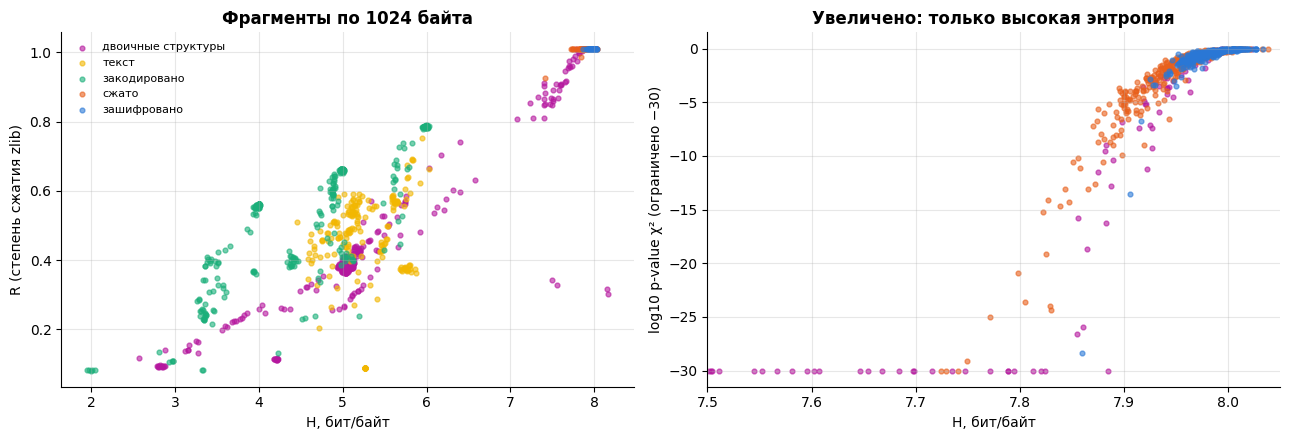

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = ["зашифровано", "сжато", "закодировано", "текст", "двоичные структуры"]
for i, c in reversed(list(enumerate(order))):            # зашифрованное рисуем поверх остальных
    d = D[D["cls"] == c]
    axes[0].scatter(d["H"], d["R"], s=12, alpha=0.6, color=PALETTE[i], label=c)
    axes[1].scatter(d["H"], np.log10(d["chi2_p"].clip(lower=1e-30)), s=12, alpha=0.6, color=PALETTE[i], label=c)
axes[0].set_xlabel("H, бит/байт"); axes[0].set_ylabel("R (степень сжатия zlib)"); axes[0].legend(frameon=False, fontsize=8)
axes[1].set_xlabel("H, бит/байт"); axes[1].set_ylabel("log10 p-value χ² (ограничено −30)")
axes[1].set_xlim(7.5, 8.05); axes[1].set_title("Увеличено: только высокая энтропия")
axes[0].set_title("Фрагменты по 1024 байта")
plt.tight_layout(); plt.show()

* Закодированное отделяется легко: энтропия упирается в потолок алфавита (hex — 4, base32 — 5, base64 — 6 бит), $R ≈ 0{,}6–0{,}8$.
* Текст и двоичные структуры — средняя энтропия и хорошая сжимаемость.
* Зашифрованное и сжатое — оба около 8 бит и не сжимаются. **χ²** помогает лишь отчасти: у части сжатых фрагментов
  p-value близко к нулю (неравномерность байтов, остатки заголовков), но у многих — такое же, как у шифртекста
  (медиана для сжатых ≈ 0,1). На 1024 байтах в ячейке ожидается всего 4 значения, тест приблизителен.
  Поэтому статистически шифр и сжатие на коротких фрагментах почти неразличимы.

## 7.4. Классификатор и статистическая мощность

In [63]:
labels = order
res, MODELS = [], {}
for n in [64, 128, 256, 512, 1024, 4096]:
    Dn = D if n == 1024 else make_dataset(n)
    MODELS[n] = RandomForestClassifier(n_estimators=300, random_state=0, class_weight="balanced").fit(Dn[FEATS], Dn["cls"])
    pred = cross_val_predict(RandomForestClassifier(n_estimators=300, random_state=0, class_weight="balanced"),
                             Dn[FEATS], Dn["cls"], groups=Dn["group"], cv=GroupKFold(5))
    cm = pd.crosstab(Dn["cls"], pred)
    enc_vs_comp = Dn["cls"].isin(["зашифровано", "сжато"])
    res.append({"n, байт": n, "точность": accuracy_score(Dn["cls"], pred),
                "шифр vs сжатие": accuracy_score(Dn.loc[enc_vs_comp, "cls"], pred[enc_vs_comp.to_numpy()]),
                "закодировано: полнота": (pred[(Dn["cls"] == "закодировано").to_numpy()] == "закодировано").mean()})
    if n == 1024:
        CM = cm
RES = pd.DataFrame(res).set_index("n, байт")
display(RES.round(3))
display(CM)

clf = MODELS[1024]
pd.Series(clf.feature_importances_, index=FEATS).sort_values(ascending=False).round(3).rename("важность признака (n = 1024)")

,точность,шифр vs сжатие,закодировано: полнота
"n, байт",,,
64,0.794,0.334,0.817
128,0.830,0.378,0.910
256,0.823,0.481,0.941
512,0.811,0.580,0.969
1024,0.806,0.650,0.972
4096,0.832,0.760,0.995


col_0,двоичные структуры,закодировано,зашифровано,сжато,текст
cls,,,,,
двоичные структуры,338,0,28,22,0
закодировано,0,410,0,0,12
зашифровано,8,0,163,129,0
сжато,15,0,100,304,0
текст,0,20,0,0,170


,важность признака (n = 1024)
MI,0.189
printable,0.169
A,0.161
H,0.149
zeros,0.129
chi2_p,0.113
R,0.090


* Текст распознаётся почти безошибочно, закодированное — с полнотой выше 0,9 уже на 128 байтах.
* **Зашифрованное и сжатое — главная трудность**: на коротких фрагментах их различение не лучше подбрасывания монеты
  (≈ 0,5), с ростом длины точность растёт, но и на 4 КБ остаётся заметно ниже единицы. Для сжатых данных решающим
  остаётся **проверка сигнатуры и попытка распаковки**.
* Учтите ограничения: эталон собран из небольшого числа источников, и сжатые форматы бывают разными
  (у JPEG, например, заметные отклонения от равномерности, у сжатия высокой степени — почти никаких).

## 7.5. Объекты расследования

### (а) Cookie перенаправления `80.77.25.175/main.php`

In [66]:
def cookies(hdr):
    c = hdr_field(hdr, b"Cookie")
    return dict(p.split("=", 1) for p in c.split("; ") if "=" in p)


def b64url(s):
    return base64.urlsafe_b64decode(s + "=" * (-len(s) % 4))


tds = OBJ[(OBJ["srv"] == "80.77.25.175") & (OBJ["dir"] == "c2s")].iloc[0]
ck = cookies(tds["hdr"])
for k, v in ck.items():
    m = measures(v.encode())
    print(f"{k} = {v[:60]}{'…' if len(v) > 60 else ''}\n   |A| = {m['A']}, H = {m['H']:.2f}, n = {m['n']}")
jwt = next(v for v in ck.values() if v.count(".") == 2)
head, payload, sign = jwt.split(".")
print("\nJWT заголовок:", b64url(head).decode())
data = json.loads(json.loads(b64url(payload))["data"])
print("JWT данные:   ", data)
print("время в токене:", pd.to_datetime(data["time"], unit="s", utc=True))

_subid = 17dk1e9d14f
   |A| = 8, H = 3.30, n = 11
34ab8 = eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJkYXRhIjoie1wic3RyZWF…
   |A| = 59, H = 5.75, n = 213

JWT заголовок: {"typ":"JWT","alg":"HS256"}
JWT данные:    {'streams': {'238': 1681917641}, 'campaigns': {'50': 1681917641}, 'time': 1681917641}
время в токене: 2023-04-19 15:20:41+00:00


Значение cookie — **JWT**: три части в base64url, разделённые точками. Первые две — просто закодированный JSON
(идентификаторы «потока» и «кампании» системы перенаправления трафика, TDS, и время первого визита);
третья — подпись HMAC (не шифрование!). Ничего не скрыто — данные только закодированы.

### (б) Первый запрос установщика IcedID к `skigimeetroc.com`

In [73]:
ice_req = OBJ[(OBJ["srv"] == "192.153.57.233") & (OBJ["dir"] == "c2s")].iloc[0]
print(ice_req["hdr"].decode("latin-1"))
ck = cookies(ice_req["hdr"])
print("_u  ->", [bytes.fromhex(x).decode() for x in ck["_u"].split(":")])
print("__io ->", "S-1-5-" + ck["__io"].replace("_", "-"), " (SID без последнего компонента — RID)")
print("_gat ->", "Windows", ck["_gat"].rsplit(".", 1)[0], "(сборка 22621 — Windows 11 22H2)")

GET / HTTP/1.1
Connection: Keep-Alive
Cookie: __gads=422998217:1:1808:131; _gid=A0CA96894E9D; _u=4445534B544F502D534646394C4A46:6373696C7661:46353431423635424230383346354633; __io=21_1181811818_1193560798_2439418475; _ga=1.591597.1635208534.1022; _gat=10.0.22621.64
Host: skigimeetroc.com


_u  -> ['DESKTOP-SFF9LJF', 'csilva', 'F541B65BB083F5F3']
__io -> S-1-5-21-1181811818-1193560798-2439418475  (SID без последнего компонента — RID)
_gat -> Windows 10.0.22621 (сборка 22621 — Windows 11 22H2)


Запрос без `User-Agent`, к корню сайта, а в cookie «замаскированы под Google Analytics» (`__gads`, `_gid`, `_ga`, `_gat`)
**сведения о заражённом хосте**: имя компьютера `DESKTOP-SFF9LJF` и пользователь `csilva` — в hex, идентификатор
безопасности (SID), версия Windows. Назначение остальных полей по трафику не установить.
### (в) Ответ `skigimeetroc.com`: «gzip», который не распаковывается

In [75]:
fake = OBJ[(OBJ["srv"] == "192.153.57.233") & (OBJ["dir"] == "s2c") & (OBJ["len"] > 0)].iloc[0]["body"]
flg = fake[3]
fname = fake[10:fake.index(b"\x00", 10)] if flg & 0x08 else b""
print("Content-Type: application/gzip; размер", len(fake), "Б")
print("Сигнатура:", fake[:2].hex(), "| метод:", fake[2], "(8 = deflate) | флаги:", bin(flg), "| имя файла в заголовке:", fname)
try:
    gzip.decompress(fake)
    print("распаковано")
except Exception as e:
    print("Распаковка:", type(e).__name__, "—", e)


def classify_object(data, n=1024):
    """Режем объект на фрагменты длины n и голосуем моделью, обученной на фрагментах той же длины.
    Если объект короче n, берём наибольшую длину из MODELS, которая в него помещается."""
    if len(data) < n:
        fits = [m for m in MODELS if m <= len(data)]
        if not fits:
            return pd.DataFrame([measures(data)]), pd.Series({"слишком коротко": 1.0})
        n = max(fits)
    parts = [data[i:i + n] for i in range(0, len(data) - n + 1, n)][:200]
    M = pd.DataFrame([measures(p) for p in parts])
    votes = pd.Series(MODELS[n].predict(M[FEATS])).value_counts(normalize=True)
    votes.attrs.update(n=n, k=len(parts))
    return M, votes


M, votes = classify_object(fake[len(fname) + 11:])
print("\nПо фрагментам 1024 Б: медианы", M[FEATS].median().round(3).to_dict())
print("Голоса классификатора:", votes.round(2).to_dict())
print("χ² для всего тела: p =", round(chi2_p(fake[len(fname) + 11:]), 3))

Content-Type: application/gzip; размер 520803 Б
Сигнатура: 1f8b | метод: 8 (8 = deflate) | флаги: 0b1000 | имя файла в заголовке: b'Tail.txt'
Распаковка: error — Error -3 while decompressing data: invalid code lengths set

По фрагментам 1024 Б: медианы {'H': 7.985, 'chi2_p': 0.484, 'A': 252.0, 'printable': 0.383, 'zeros': 0.004, 'MI': -0.0, 'R': 1.011}
Голоса классификатора: {'зашифровано': 0.52, 'сжато': 0.48, 'двоичные структуры': 0.0}
χ² для всего тела: p = 0.459


Заголовок gzip корректный (сигнатура, метод deflate, имя `Tail.txt`), но распаковка падает на первом блоке.
Внутри — данные с энтропией 8,00 и **«нормальным» p-value χ² на 0,5 МБ**: так выглядит шифртекст, а не deflate.
Это зашифрованная нагрузка IcedID, замаскированная под сжатый файл.

### (г) Архив, скачанный `.138`

In [76]:
z_obj = OBJ[(OBJ["srv"] == "66.29.147.117") & (OBJ["dir"] == "s2c") & (OBJ["len"] > 0)].iloc[0]
layer1 = gzip.decompress(z_obj["body"])                       # Content-Encoding: gzip
zf = zipfile.ZipFile(io.BytesIO(layer1))
rows = [{"слой": "HTTP-тело (gzip)", "байт": z_obj["len"], **{k: v for k, v in measures(z_obj["body"]).items() if k in FEATS}},
        {"слой": "после gzip: ZIP", "байт": len(layer1), **{k: v for k, v in measures(layer1).items() if k in FEATS}}]
for info in zf.infolist():
    content = zf.read(info)
    rows.append({"слой": f"файл в ZIP: {info.filename}", "байт": len(content),
                 **{k: v for k, v in measures(content).items() if k in FEATS}})
display(pd.DataFrame(rows).set_index("слой").round(3))
print("Классификатор по фрагментам файла:", classify_object(content, n=512)[1].round(2).to_dict())
digits = np.isin(np.frombuffer(content, np.uint8), np.frombuffer(b"0123456789abcdefABCDEF", np.uint8)).mean()
print(f"Доля символов 0–9, a–f, A–F во всём файле: {digits:.0%}")
hex_runs = [len(m.group(0)) for m in re.finditer(rb"[0-9a-fA-F]{40,}", content)]
b64_runs = [len(m.group(0)) for m in re.finditer(rb"[A-Za-z0-9+/=]{40,}", content)]
print(f"Строки из hex-символов длиной ≥ 40: {len(hex_runs)} шт., {sum(hex_runs)} байт "
      f"({sum(hex_runs) / len(content):.0%} файла); base64-подобные: {len(b64_runs)} шт., {sum(b64_runs)} байт")

,байт,H,chi2_p,A,printable,zeros,MI,R
слой,,,,,,,,
HTTP-тело (gzip),5673,8.000,0.487,256,0.381,0.006,-0.001,1.002
после gzip: ZIP,5665,7.981,0.000,256,0.390,0.013,0.057,0.999
файл в ZIP: Complaint_Copy_634917.wsf,16173,4.878,0.000,91,0.999,0.000,1.414,0.347


Классификатор по фрагментам файла: {'закодировано': 0.52, 'текст': 0.48}
Доля символов 0–9, a–f, A–F во всём файле: 38%
Строки из hex-символов длиной ≥ 40: 2 шт., 2824 байт (17% файла); base64-подобные: 2 шт., 2824 байт


In [77]:
content

b'\n"And now which is which?" she said to herself, and nibbled a little of the right-hand bit to try the effect. The next moment she felt a violent blow underneath her chin\xe2\x80\x94it had struck her foot!\n\nShe was a good deal frightened by this very sudden change, as she was shrinking rapidly; so she set to work at once to eat some of the other bit. Her chin was pressed so closely against her foot that there was hardly room to open her mouth; but she did it at last and managed to swallow a morsel of the left-hand bit....\n\n"Come, my head\'s free at last!" said Alice; but all she could see, when she looked down, was an immense length of neck, which seemed to rise like a stalk out of a sea of green leaves that lay far below her.\n\n"Where have my shoulders got to? And oh, my poor hands, how is it I can\'t see you?" She was delighted to find that she began shrinking directly. As soon as she was small enough to get through the door, she ran out of the house and found quite a crowd of

Два слоя сжатия (HTTP gzip поверх ZIP), внутри — 16 КБ **текста**: `.wsf` — Windows Script File, сценарий JScript/VBScript,
который запускается двойным щелчком. Это вредоносный код!
Состав файла:
это открытый текст, в котором около шестой части занимают две длинные hex-строки — **закодированные** данные,
а символы шестнадцатеричного алфавита составляют больше трети файла. Поэтому классификатор делит голоса между
«текстом» и «закодированным»: по статистике байтов обфусцированный сценарий наполовину похож на hex.
Длинные строки в hex/base64 внутри сценария — типичный приём обфускации: полезная нагрузка не видна при беглом просмотре. Через 28 с после загрузки `.138` обращается по IP к `85.239.53.73:80`, и сервер не отвечает —
похоже, что сценарий был запущен, но следующую стадию получить не удалось. Подтвердить это можно только данными с хоста (EDR, журналы).

### (д) BackConnect на 443/tcp

Разберём сеансы с `193.149.176.100` по сообщениям (сегментам TCP): длина, энтропия, доля печатаемых символов.

In [78]:
bc_rows = []
for sid in sess.loc[sess["srv"] == "193.149.176.100", "sid"]:
    for d in ("c2s", "s2c"):
        for seq, (ts, pl) in STREAMS[sid][d].items():
            m = measures(pl)
            bc_rows.append({"sid": sid, "t": pd.to_datetime(ts, unit="s", utc=True), "dir": d, "len": len(pl),
                            "H": m["H"], "printable": m["printable"], "text": pl.decode("utf-8", "replace")
                            if m["printable"] > 0.9 else ""})
BC = pd.DataFrame(bc_rows).sort_values("t")
BC["вид"] = np.select([BC["len"] < 32, BC["printable"] > 0.9, BC["H"] >= 7.0],
                      ["слишком коротко", "текст", "высокая энтропия"], "двоичные данные")
display(BC.groupby(["sid", "dir", "вид"]).agg(сообщений=("len", "size"), длины=("len", lambda s: sorted(set(s))[:6])))

/tmp/ipykernel_1999/2236604686.py:23: RuntimeWarning: invalid value encountered in divide
  pab = np.bincount(a[:-1] * 256 + a[1:], minlength=65536).reshape(256, 256) / (len(a) - 1)


сообщений                  длины
sid  dir вид                                               
1900 c2s высокая энтропия          1                  [249]
         слишком коротко          34                   [17]
     s2c слишком коротко          37                   [17]
1901 c2s высокая энтропия          1                  [249]
         слишком коротко           9       [2, 3, 4, 6, 25]
         текст                     5  [33, 37, 66, 84, 208]
     s2c слишком коротко           2                    [1]
         текст                     1                   [39]
1903 c2s высокая энтропия          1                  [249]
         слишком коротко           5             [4, 5, 25]
         текст                     2              [66, 413]
     s2c слишком коротко           4             [1, 5, 10]

In [79]:
for _, r in BC[(BC["вид"] != "высокая энтропия") & (BC["printable"] > 0.9)].iterrows():
    arrow = "C2 → хост" if r["dir"] == "s2c" else "хост → C2"
    print(f"{r['t']:%H:%M:%S}  sid {r['sid']}  {arrow}: {r['text'].strip()[:200]!r}")

20:49:11  sid 1901  C2 → хост: ''
20:49:11  sid 1901  хост → C2: '+'
20:49:12  sid 1901  C2 → хост: 'c'
20:49:12  sid 1901  хост → C2: 'Active code page: 65001'
20:49:12  sid 1901  хост → C2: ''
20:49:12  sid 1901  хост → C2: 'c:\\>'
20:49:17  sid 1901  C2 → хост: 'net group "Domain Computers" /domain'
20:49:17  sid 1901  хост → C2: 'net group "Domain Computers" /domain'
20:49:17  sid 1901  хост → C2: 'The request will be processed at a domain controller for domain boogienights.live.'
20:49:17  sid 1901  хост → C2: ''
20:49:17  sid 1901  хост → C2: 'Group name     Domain Computers'
20:49:17  sid 1901  хост → C2: 'Comment        All workstations and servers joined to the domain'
20:49:17  sid 1901  хост → C2: ''
20:49:17  sid 1901  хост → C2: 'Members\r\n\r\n-------------------------------------------------------------------------------\r\nDESKTOP-JAL4D68$         DESKTOP-RETP4BU$         DESKTOP-SFF9LJF$         \r\nThe command completed successfu'
20:49:17  sid 1901  хост → C2: ''
20:

Картина одного «нестандартного протокола на 443»:

* каждое соединение начинается с **249 байт высокой энтропии** (зашифрованное приветствие/аутентификация бота);
* управляющий сеанс (`sid` с 17-байтовыми сообщениями) обменивается сообщениями одинаковой длины раз в минуту —
  по 17 байтам статистика бессильна (максимальная возможная оценка энтропии — $\log_2 17 ≈ 4{,}1$ бит). Байты
  не печатаемые и не повторяются от сообщения к сообщению — вероятно, шифр, но доказать это по таким данным нельзя;
  здесь работает поведенческий признак «постоянная длина, постоянный период»;
* в двух других сеансах команды и ответы идут **открытым текстом**: оператор запускает `cmd.exe`
  (`Active code page: 65001`), выполняет `net group "Domain Computers" /domain` (список компьютеров домена — запрос к DC
  по SMB, тот самый сеанс из шага 6.3), затем модуль просмотра файлов: `DISK`, `CDDIR Z:\`, `CDDIR C:\`.

Итак, на одном порту и в одном протоколе соседствуют высокоэнтропийные данные (приветствие; вероятно — управляющий
канал) и открытый текст (команды).

### (е) Остальной трафик: C2 по TLS и служебный трафик домена

In [80]:
HEX_SET = set(b"0123456789abcdefABCDEF:")
B64URL_SET = set(b"ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz0123456789-_.=")
B64_SET = set(b"ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz0123456789+/=\r\n")


def alphabet_check(x):
    """Кандидат на кодирование по алфавиту (подтверждение — успешное декодирование)."""
    A = set(x.strip())
    if A <= HEX_SET and len(x.strip().replace(b":", b"")) % 2 == 0:
        return "hex"
    if A <= B64URL_SET:
        return "base64url"
    if A <= B64_SET:
        return "base64"
    return "—"


summary = []


def add(name, data, declared, note=""):
    if not data:
        return
    M, votes = classify_object(data)
    summary.append({"объект": name, "заявлено": declared, "байт": len(data),
                    "H": round(H_bytes(data), 2), "χ² p": round(chi2_p(data[:65536]), 3),
                    "R": round(len(zlib.compress(data[:65536], 9)) / len(data[:65536]), 2),
                    "классификатор": votes.index[0], "доля голосов": round(votes.iloc[0], 2),
                    "фрагментов": f"{votes.attrs.get('k', 1)} × {votes.attrs.get('n', len(data))} Б",
                    "все голоса": ", ".join(f"{k} {v:.0%}" for k, v in votes.items()),
                    "алфавит": alphabet_check(data), "вывод": note})


ask = sess[(sess["srv"] == "104.168.53.18")].nlargest(1, "bytes")["sid"].iloc[0]
add("askamoshopsi.com, загрузка 2 МБ", tls_appdata(join(STREAMS[ask]["s2c"])), "TLS",
    "шифрование TLS; содержимое недоступно, видны объём и сертификат")
beacons = sess[sess["srv"] == "217.199.121.56"]["sid"]
add("skansnekssky.com, 69 опросов", b"".join(tls_appdata(join(STREAMS[s]["s2c"])) for s in beacons), "TLS",
    "шифрование TLS; признаки C2 — только поведенческие")
add("skigimeetroc.com, «gzip»", fake[len(fname) + 11:], "application/gzip", "шифртекст под видом gzip")
add("cotecsecuritygroup.com, zip", z_obj["body"], "application/zip + gzip",
    "сжато: распаковка удалась (статистика ошибается — сжатие поверх сжатия)")
add("файл .wsf из zip", content, "—", "текст с закодированными (hex) вставками")
add("cookie TDS (JWT)", jwt.encode(), "Cookie", "base64url: JSON + подпись")
add("cookie IcedID `_u`", ck["_u"].encode(), "Cookie", "hex: имя хоста и пользователя")
add("BackConnect: команды и ответы", b"".join(BC.loc[BC["вид"] == "текст", "text"].str.encode("utf-8")), "443/tcp",
    "открытый текст")
add("BackConnect: приветствия 249 Б", b"".join(STREAMS[s]["c2s"][min(STREAMS[s]["c2s"])][1]
                                               for s in sess.loc[sess["srv"] == "193.149.176.100", "sid"]), "443/tcp",
    "высокая энтропия: шифр или сжатие — по 747 байтам не различить")
dc_ldap = b"".join(join(STREAMS[s]["s2c"]) for s in dc_sids if sess.loc[s, "sport"] == 389)
dc_smb = b"".join(join(STREAMS[s]["s2c"]) for s in dc_sids if sess.loc[s, "sport"] == 445)
add("LDAP от контроллера домена", dc_ldap, "LDAP (389)", "")
add("SMB от контроллера домена", dc_smb, "SMB (445)", "")
SUMMARY = pd.DataFrame(summary).set_index("объект")
SUMMARY

,заявлено,байт,H,χ² p,R,классификатор,доля голосов,фрагментов,все голоса,алфавит,вывод
объект,,,,,,,,,,,
"askamoshopsi.com, загрузка 2 МБ",TLS,1905141,8.00,0.721,1.00,зашифровано,0.52,200 × 1024 Б,"зашифровано 52%, сжато 48%",—,"шифрование TLS; содержимое недоступно, видны объём и сертификат"
"skansnekssky.com, 69 опросов",TLS,12063,8.00,0.601,1.00,сжато,0.55,11 × 1024 Б,"сжато 55%, зашифровано 45%",—,шифрование TLS; признаки C2 — только поведенческие
"skigimeetroc.com, «gzip»",application/gzip,520784,8.00,0.445,1.00,зашифровано,0.52,200 × 1024 Б,"зашифровано 52%, сжато 48%, двоичные структуры 0%",—,шифртекст под видом gzip
"cotecsecuritygroup.com, zip",application/zip + gzip,5673,8.00,0.487,1.00,зашифровано,0.80,5 × 1024 Б,"зашифровано 80%, сжато 20%",—,сжато: распаковка удалась (статистика ошибается — сжатие поверх сж...
файл .wsf из zip,—,16173,4.88,0.000,0.35,закодировано,0.80,15 × 1024 Б,"закодировано 80%, текст 20%",—,текст с закодированными (hex) вставками
cookie TDS (JWT),Cookie,213,5.75,0.000,0.85,текст,1.00,1 × 128 Б,текст 100%,base64url,base64url: JSON + подпись
cookie IcedID `_u`,Cookie,76,3.34,0.000,0.82,текст,1.00,1 × 64 Б,текст 100%,hex,hex: имя хоста и пользователя
BackConnect: команды и ответы,443/tcp,946,5.33,0.000,0.53,текст,1.00,1 × 512 Б,текст 100%,—,открытый текст
BackConnect: приветствия 249 Б,443/tcp,747,8.02,0.986,1.01,сжато,1.00,1 × 512 Б,сжато 100%,—,высокая энтропия: шифр или сжатие — по 747 байтам не различить


Что показывает сводка:

* **Статистика без проверки формата ошибается в обе стороны.** Настоящий zip (сжатие поверх сжатия) классификатор
  назвал «зашифровано» — а распаковка удалась. «gzip» с `skigimeetroc.com` выглядит так же — а распаковка не удалась.
  Решает сочетание: сигнатура → попытка распаковать → статистика того, что не распаковалось.
* Короткие строки (cookie: 76 и 213 байт) классификатор, обученный на фрагментах 64–128 байт, называет «текстом»:
  на таких длинах статистика ненадёжна. Здесь лучше работает простая **проверка алфавита** (столбец «алфавит»):
  только `0-9A-F` — кандидат в hex, только `A-Za-z0-9-_` — в base64url. Окончательное подтверждение — успешное
  **декодирование**: закодированное нужно не классифицировать, а читать.
* На одном порту 443 соседствуют TLS (C2), собственное шифрование (приветствия BackConnect) и открытый текст (команды).
* Для сравнения — служебный трафик домена: SMB и LDAP от контроллера — двоичные структуры; лишь около 6 % фрагментов
  LDAP высокоэнтропийные (вероятно, сеансы LDAP с подписью и шифрованием SASL, которые использует Windows).
  Высокая энтропия встречается и в норме; признак атаки — **несоответствие ожиданию**: шифр там, где протокол текстовый
  (HTTP, DNS), сигнатура сжатия без возможности распаковки, «не-TLS» на порту TLS.



---
# 8. Хронология, IOC и выводы

## 8.1. Хронология

Соберём находки всех шагов в одну временную шкалу. Каждое событие — с источником (шаг практики) и фильтром Wireshark,
по которому его можно проверить.

In [81]:
def first_session(srv, cli=None, port=None):
    m = sess["srv"] == srv
    if cli:
        m &= sess["cli"] == cli
    if port:
        m &= sess["sport"] == port
    return sess[m].sort_values("t").iloc[0]


ev = []


def event(t, host, what, step, sessions=None, flt=None):
    ev.append({"время (UTC)": pd.Timestamp(t).strftime("%H:%M:%S"), "хост": host, "событие": what, "шаг": step,
               "фильтр Wireshark": flt or (display_filter(sessions) if sessions is not None else "")})


s = first_session("80.77.25.175")
event(s["t"], s["cli"], "HTTP по IP к 80.77.25.175/main.php: JWT-cookie системы перенаправлений, ответ 302", "ч.1 §5, 7(а)",
      sess[sess["sid"] == s["sid"]])
loc = app[(app["kind"] == "http_resp") & app["location"].fillna("").str.contains("firebasestorage")].iloc[0]["location"]
print("Location в ответе 302:", loc)
fb = sess["srv"].map(lambda ip: ip in pdns.index and "firebasestorage.googleapis.com" in pdns.loc[ip, "names"])
s = sess[fb].sort_values("t").iloc[0]
event(s["t"], s["cli"], "загрузка по HTTPS с firebasestorage.googleapis.com: Scan_Inv.zip (имя — из Location ответа 302)",
      "ч.1 §5, 6.1", sess[sess["sid"] == s["sid"]])
s = first_session("54.145.90.68")
event(s["t"], s["cli"], "загрузка сертификата www.ssl.com (вероятно, проверка цифровой подписи запускаемого файла)",
      "6.1", sess[sess["sid"] == s["sid"]])
s = first_session("192.153.57.233")
event(s["t"], s["cli"], "GET / к skigimeetroc.com: в cookie hex-кодом имя хоста и пользователя; ответ — шифртекст под видом gzip",
      "7(б), 7(в)", sess[sess["sid"] == s["sid"]])
s = first_session("104.168.53.18")
event(s["t"], s["cli"], "TLS к askamoshopsi.com, самоподписанный сертификат, загрузка ≈ 2 МБ", "1.2, 5.2",
      sess[sess["srv"] == "104.168.53.18"])
s = first_session("217.199.121.56")
event(s["t"], s["cli"], "начало биконинга на skansnekssky.com: 69 сеансов TLS каждые ≈ 302 с до конца записи", "4, 5.3",
      sess[sess["srv"] == "217.199.121.56"])
s = sess[sess["cli"] == "10.4.19.138"].sort_values("t").iloc[0]
event(s["t"], "10.4.19.138", "включение компьютера irichardson, загрузка обновлений", "1.1, 2", flt="ip.addr==10.4.19.138")
q = app[(app["kind"] == "dns_query") & app["name"].str.contains("joansstudio")].sort_values("dt")
event(q["dt"].iloc[0], "10.4.19.138", "DNS-запросы к *.joansstudio.store → NXDOMAIN (26 ответов)", "3",
      flt='dns.qry.name contains "joansstudio"')
s = first_session("66.29.147.117")
event(s["t"], s["cli"], "загрузка zip с cotecsecuritygroup.com: внутри сценарий .wsf с hex-строками", "7(г)",
      sess[sess["sid"] == s["sid"]])
s = first_session("85.239.53.73")
event(s["t"], s["cli"], "попытка соединения по IP с 85.239.53.73:80 — SYN без ответа, соединение не установлено", "3, 5.2",
      sess[sess["sid"] == s["sid"]])
sni_frame = app[(app["kind"] == "tls_sni") & (app["name"] == "spakernakurs.com")]["no"].iloc[0]
s = sess[sess["nos"].map(lambda nos: sni_frame in nos)].iloc[0]                      # сеанс, где SNI = spakernakurs.com
event(s["t"], s["cli"], "повторное обращение к 104.168.53.18 под другим именем (spakernakurs.com), длительный сеанс", "6.1",
      sess[sess["sid"] == s["sid"]])
for sid in sess.loc[sess["srv"] == "193.149.176.100", "sid"]:
    s = sess.loc[sid]
    kind = {0: "управляющий канал (17-байтовые сообщения раз в минуту)", 1: "командная строка: net group \"Domain Computers\" /domain",
            2: "просмотр файловой системы: DISK, CDDIR Z:\\, CDDIR C:\\"}
    i = list(sess.loc[sess["srv"] == "193.149.176.100", "sid"]).index(sid)
    event(s["t"], s["cli"], f"BackConnect на 193.149.176.100:443 (не TLS): {kind[i]}", "ч.1 §5, 7(д)",
          sess[sess["sid"] == sid])
s = sess[(sess["cli"] == "10.4.19.136") & (sess["srv"] == "10.4.19.19") & (sess["sport"] == 445)
         & (sess["t"] > bc["t"].min())].sort_values("t").iloc[0]
event(s["t"], s["cli"], "SMB к контроллеру домена в 2,6 раза больше обычного — выполнение net group (запрос к домену)", "6.3",
      sess[sess["sid"] == s["sid"]])
TL = pd.DataFrame(ev).sort_values("время (UTC)").reset_index(drop=True)
with pd.option_context("display.max_colwidth", 120):
    display(TL[["время (UTC)", "хост", "событие", "шаг"]])

Location в ответе 302: https://firebasestorage.googleapis.com/v0/b/serene-cathode-377701.appspot.com/o/XSjwp6O0pq%2FScan_Inv.zip?alt=media&token=a716bdce-1373-44ed-ae89-fdabafa31c61


,время (UTC),хост,событие,шаг
0,15:31:07,10.4.19.136,"HTTP по IP к 80.77.25.175/main.php: JWT-cookie системы перенаправлений, ответ 302","ч.1 §5, 7(а)"
1,15:31:14,10.4.19.136,загрузка по HTTPS с firebasestorage.googleapis.com: Scan_Inv.zip (имя — из Location ответа 302),"ч.1 §5, 6.1"
2,15:34:33,10.4.19.136,"загрузка сертификата www.ssl.com (вероятно, проверка цифровой подписи запускаемого файла)",6.1
3,15:35:39,10.4.19.136,GET / к skigimeetroc.com: в cookie hex-кодом имя хоста и пользователя; ответ — шифртекст под видом gzip,"7(б), 7(в)"
4,15:36:41,10.4.19.136,"TLS к askamoshopsi.com, самоподписанный сертификат, загрузка ≈ 2 МБ","1.2, 5.2"
5,15:36:44,10.4.19.136,начало биконинга на skansnekssky.com: 69 сеансов TLS каждые ≈ 302 с до конца записи,"4, 5.3"
6,17:02:29,10.4.19.138,"включение компьютера irichardson, загрузка обновлений","1.1, 2"
7,17:12:40,10.4.19.138,DNS-запросы к *.joansstudio.store → NXDOMAIN (26 ответов),3
8,17:17:10,10.4.19.138,загрузка zip с cotecsecuritygroup.com: внутри сценарий .wsf с hex-строками,7(г)
9,17:17:38,10.4.19.138,"попытка соединения по IP с 85.239.53.73:80 — SYN без ответа, соединение не установлено","3, 5.2"


## 8.2. Индикаторы компрометации

In [82]:
ioc = [
    ("ip", "80.77.25.175", "система перенаправления трафика (main.php)"),
    ("domain", "skigimeetroc.com", "загрузчик IcedID (GET / с данными хоста в cookie)"),
    ("ip", "192.153.57.233", "skigimeetroc.com"),
    ("domain", "askamoshopsi.com", "C2 IcedID (TLS, самоподписанный сертификат)"),
    ("domain", "spakernakurs.com", "то же IP, что askamoshopsi.com"),
    ("ip", "104.168.53.18", "askamoshopsi.com / spakernakurs.com"),
    ("domain", "skansnekssky.com", "C2 IcedID, биконинг 5 мин"),
    ("ip", "217.199.121.56", "skansnekssky.com"),
    ("ip", "193.149.176.100", "BackConnect на 443/tcp без TLS"),
    ("tls", "CN=localhost, O=Internet Widgits Pty Ltd (самоподписанный)",
     "сертификат C2; O — значение организации по умолчанию в OpenSSL"),
    ("domain", "nobpc.joansstudio.store", "NXDOMAIN перед загрузкой zip (.138)"),
    ("domain", "dlmfz.joansstudio.store", "NXDOMAIN перед загрузкой zip (.138)"),
    ("domain", "cotecsecuritygroup.com", "zip с .wsf (.138)"),
    ("ip", "66.29.147.117", "cotecsecuritygroup.com"),
    ("ip", "85.239.53.73", "соединение по IP после загрузки zip (.138), не установлено"),
    ("url", "hxxps://firebasestorage.googleapis[.]com/v0/b/serene-cathode-377701.appspot.com/o/XSjwp6O0pq%2FScan_Inv.zip",
     "архив первой стадии (облако Google, ссылка из ответа 302)"),
    ("url", "hxxp://cotecsecuritygroup[.]com/wicd/643d0491bcea1.zip", "архив Complaint_Copy_634917.wsf"),
]
IOC = pd.DataFrame(ioc, columns=["тип", "значение", "контекст"])
IOC["в TI-фиде части 1"] = IOC["значение"].isin(pd.read_csv(ENR / "ti_feed_training.csv")["indicator"])
IOC.to_csv(OUT / "icedid_ioc.csv", index=False, encoding="utf-8-sig")
print(f"Индикаторов: {len(IOC)}, из них было в учебном TI-фиде: {IOC['в TI-фиде части 1'].sum()}")
TL.to_csv(OUT / "icedid_timeline.csv", index=False, encoding="utf-8-sig")
IOC

Индикаторов: 17, из них было в учебном TI-фиде: 3


,тип,значение,контекст,в TI-фиде части 1
0,ip,80.77.25.175,система перенаправления трафика (main.php),False
1,domain,skigimeetroc.com,загрузчик IcedID (GET / с данными хоста в cookie),False
2,ip,192.153.57.233,skigimeetroc.com,False
3,domain,askamoshopsi.com,"C2 IcedID (TLS, самоподписанный сертификат)",True
4,domain,spakernakurs.com,"то же IP, что askamoshopsi.com",False
5,ip,104.168.53.18,askamoshopsi.com / spakernakurs.com,False
6,domain,skansnekssky.com,"C2 IcedID, биконинг 5 мин",True
7,ip,217.199.121.56,skansnekssky.com,False
8,ip,193.149.176.100,BackConnect на 443/tcp без TLS,True
9,tls,"CN=localhost, O=Internet Widgits Pty Ltd (самоподписанный)",сертификат C2; O — значение организации по умолчанию в OpenSSL,False


В учебном TI-фиде было лишь 3 индикатора из таблицы. Остальные получены анализом трафика — именно это и есть
ценность расследования для других организаций: новые индикаторы можно отдать в фиды.

## 8.3. Ответы на вопросы расследования

1. **Скомпрометирован `10.4.19.136`** (`DESKTOP-SFF9LJF`, пользователь `csilva`): с 15:35:39 UTC установщик IcedID
   отправляет сведения о хосте, с 15:36:41 работает C2 по TLS, с 15:36:44 до конца записи — биконинг каждые 5 мин.
   **`10.4.19.138`** (`DESKTOP-RETP4BU`, `irichardson`) — **попытка заражения**: в 17:17 скачан zip со сценарием `.wsf`,
   через 28 с — попытка соединения по IP (`85.239.53.73`), которая не установилась. По трафику успешного заражения нет, но хост требует проверки
   средствами EDR. `10.4.19.143` признаков компрометации не имеет.
2. **Цепочка доставки на `.136`**: система перенаправлений `80.77.25.175` (15:31:08) → `302` на архив `Scan_Inv.zip`
   в Firebase Storage (HTTPS, содержимое не видно) → запуск установщика → `skigimeetroc.com` (зашифрованная нагрузка под видом gzip) →
   C2 `askamoshopsi.com` → `skansnekssky.com`.
3. **Действия злоумышленника**: через 5 ч после заражения (20:48) — BackConnect: командная строка, разведка домена
   (`net group "Domain Computers" /domain` → запрос к контроллеру домена по SMB), просмотр дисков `C:` и `Z:`.
   Горизонтального перемещения между рабочими станциями и сканирования сети в дампе нет.
4. **Данные**: сведения о хосте переданы **закодированными** (hex, cookie), команды BackConnect и их результаты —
   **открытым текстом**, нагрузка IcedID и трафик C2 — **зашифрованы** (собственное шифрование под видом gzip и TLS).
   Сжатыми были легитимные загрузки и архивы с вредоносным содержимым: `Scan_Inv.zip` на `.136` (по HTTPS, само
   содержимое не видно) и zip со сценарием на `.138`. Утечки файлов в дампе не видно,
   но оператор получил список компьютеров домена и структуру дисков.
5. **IOC** — таблица 8.2 (`../pcaps/out/icedid_ioc.csv`), хронология — `../pcaps/out/icedid_timeline.csv`.

**Рекомендации**: изолировать `.136`, сменить пароль `csilva`, проверить `.138` (запуск `.wsf`, автозагрузка),
заблокировать IOC на периметре, искать индикаторы в журналах DNS и прокси за предыдущие дни, обратить внимание на
сетевой диск `Z:` — к нему у оператора был доступ.